# 03 - Analise Exploratoria de Dados (EDA)

Cobre as 5 frentes de estatistica descritiva da Aula 2 (frequencia,
localidade, dispersao, distribuicao/forma e correlacao) sobre o CICIDS2017
ja limpo e rotulado - com o maximo de profundidade possivel, ja que essa
etapa e a base de tudo que vem depois (selecao de atributos e modelagem).
Os resultados aqui sao a fonte; a versao redigida esta no relatorio final
(`docs/`).

**Classificacao de atributos (Aula 2, "armadilha classica"):** `Protocol`
(so 3 valores: 6=TCP, 17=UDP, 0=outro) e `Dst Port` sao numericos na coluna
mas qualitativos nominais no significado - media/desvio padrao/correlacao
de Pearson nao fazem sentido neles (mesmo problema do exemplo "media dos
Ids" da aula). Por isso ficam de fora do `describe()` e da matriz de
correlacao, e recebem tratamento de frequencia a parte.

**O que tem de novo aqui em relacao a uma EDA basica:** alem do
`describe()`/boxplot/histograma/correlacao pooled (dataset inteiro
misturado), quebramos varias analises por classe (BENIGN vs ataque) - e
essa e a diferenca que importa pra um projeto de classificacao: a forma
como cada atributo se comporta *dentro* de cada classe e o que realmente
vai alimentar a etapa de Analise, nao so a forma agregada.

In [1]:
from pathlib import Path
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from IPython.display import Image, display

IN_PATH = Path.cwd().parent / "dados" / "processado" / "dataset_rotulado.parquet"
FIG_DIR = Path.cwd().parent / "resultados" / "figuras"
MET_DIR = Path.cwd().parent / "resultados" / "metricas"
FIG_DIR.mkdir(parents=True, exist_ok=True)
MET_DIR.mkdir(parents=True, exist_ok=True)

ATRIBUTOS_QUALITATIVOS_NOMINAIS = ["Protocol", "Dst Port"]

COR_BENIGN = "#4C72B0"
COR_ATAQUE = "#C44E52"

ATRIBUTOS_CHAVE = [
    "Flow Duration",
    "Total Fwd Packet",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Packet Length Mean",
    "SYN Flag Count",
    "Fwd Packet Length Mean",
    "Bwd Packet Length Mean",
    "Flow IAT Mean",
    "FWD Init Win Bytes",
    "Down/Up Ratio",
    "ACK Flag Count",
]

ATRIBUTOS_PAIRPLOT = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Packet Length Mean",
    "Fwd Packet Length Mean",
    "Flow IAT Mean",
]


def limites_iqr(serie: pd.Series) -> tuple[float, float, float]:
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return iqr, q1 - 1.5 * iqr, q3 + 1.5 * iqr


def salvar_e_mostrar(fig, nome_arquivo: str) -> None:
    """Salva a figura em PNG e exibe a imagem de verdade na celula (o backend
    Agg nao tem repr rico no Jupyter, so exibir 'fig' so imprime o texto
    "<Figure size ...>" em vez da imagem)."""
    caminho = FIG_DIR / nome_arquivo
    fig.savefig(caminho, dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(caminho)))

In [2]:
df = pd.read_parquet(IN_PATH)
df.shape

(1913029, 82)

## 1. Frequencia

Distribuicao de classes (`Label`) e tabela de frequencia dos dois
atributos qualitativos nominais (`Protocol`, `Dst Port`) - a moda e a
unica medida de localidade que funciona direto em dado qualitativo
(Aula 2), por isso e isso que reportamos pra eles, nao media/desvio.
Tambem cruzamos os atributos qualitativos com o alvo (BENIGN vs ataque),
ja que "frequencia" nao precisa parar no atributo isolado.

In [3]:
contagem = df["Label"].value_counts()
contagem.to_csv(MET_DIR / "distribuicao_classes.csv", header=["contagem"])
print(f"Moda de Label (classe mais frequente): {contagem.idxmax()} ({contagem.max():,} fluxos)")
contagem

Moda de Label (classe mais frequente): BENIGN (1,548,036 fluxos)


Label
BENIGN                        1548036
DoS Hulk                       158469
DDoS                            95123
PortScan                        90583
DoS GoldenEye                    7567
FTP-Patator                      3973
DoS slowloris                    3596
SSH-Patator                      2980
DoS Slowhttptest                 1731
Bot                               738
Web Attack - Brute Force          151
Infiltration                       32
Web Attack - XSS                   27
Web Attack - Sql Injection         12
Heartbleed                         11
Name: count, dtype: int64

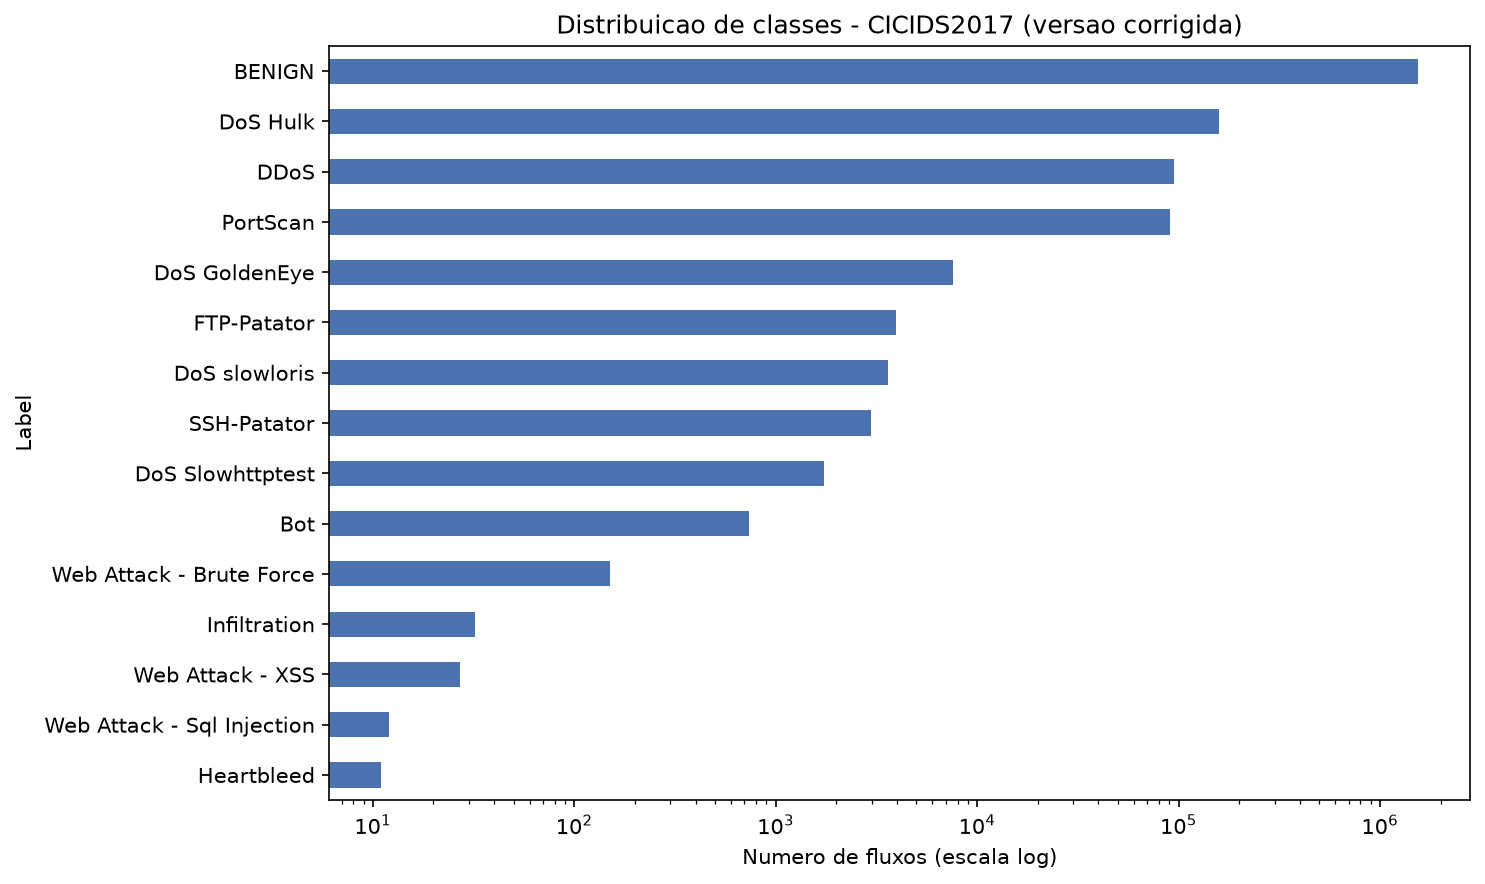

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
contagem.plot(kind="barh", ax=ax, color=COR_BENIGN)
ax.set_xscale("log")
ax.set_xlabel("Numero de fluxos (escala log)")
ax.set_title("Distribuicao de classes - CICIDS2017 (versao corrigida)")
ax.invert_yaxis()
fig.tight_layout()
salvar_e_mostrar(fig, "distribuicao_classes.png")

In [5]:
freq_protocol = df["Protocol"].value_counts()
freq_protocol.to_csv(MET_DIR / "frequencia_protocol.csv", header=["contagem"])
freq_dst_port = df["Dst Port"].value_counts().head(20)
freq_dst_port.to_csv(MET_DIR / "frequencia_dst_port_top20.csv", header=["contagem"])
freq_protocol

Protocol
6.0     996125
17.0    915334
0.0       1570
Name: count, dtype: int64

### Portas e protocolo por classe

As 10 portas de destino mais frequentes no dataset, quebradas por
BENIGN vs ataque - mostra se algum servico concentra mais trafego
malicioso que o esperado pela proporcao geral (19,1% ataque).

In [6]:
top_ports = df["Dst Port"].value_counts().head(10).index
tab_portas = pd.crosstab(df["Dst Port"], df["Label_binario"]).reindex(top_ports)
tab_portas.columns = ["BENIGN", "Ataque"]
tab_portas["pct_ataque"] = (tab_portas["Ataque"] / (tab_portas["BENIGN"] + tab_portas["Ataque"]) * 100).round(2)
tab_portas.to_csv(MET_DIR / "portas_por_classe.csv")
tab_portas

,BENIGN,Ataque,pct_ataque
Dst Port,,,
53.0,882044,101,0.01
80.0,173638,266988,60.59
443.0,389625,146,0.04
123.0,21278,1,0.00
22.0,5297,3223,37.83
21.0,2589,4216,61.95
389.0,5084,88,1.70
88.0,4020,86,2.09
137.0,3221,0,0.00


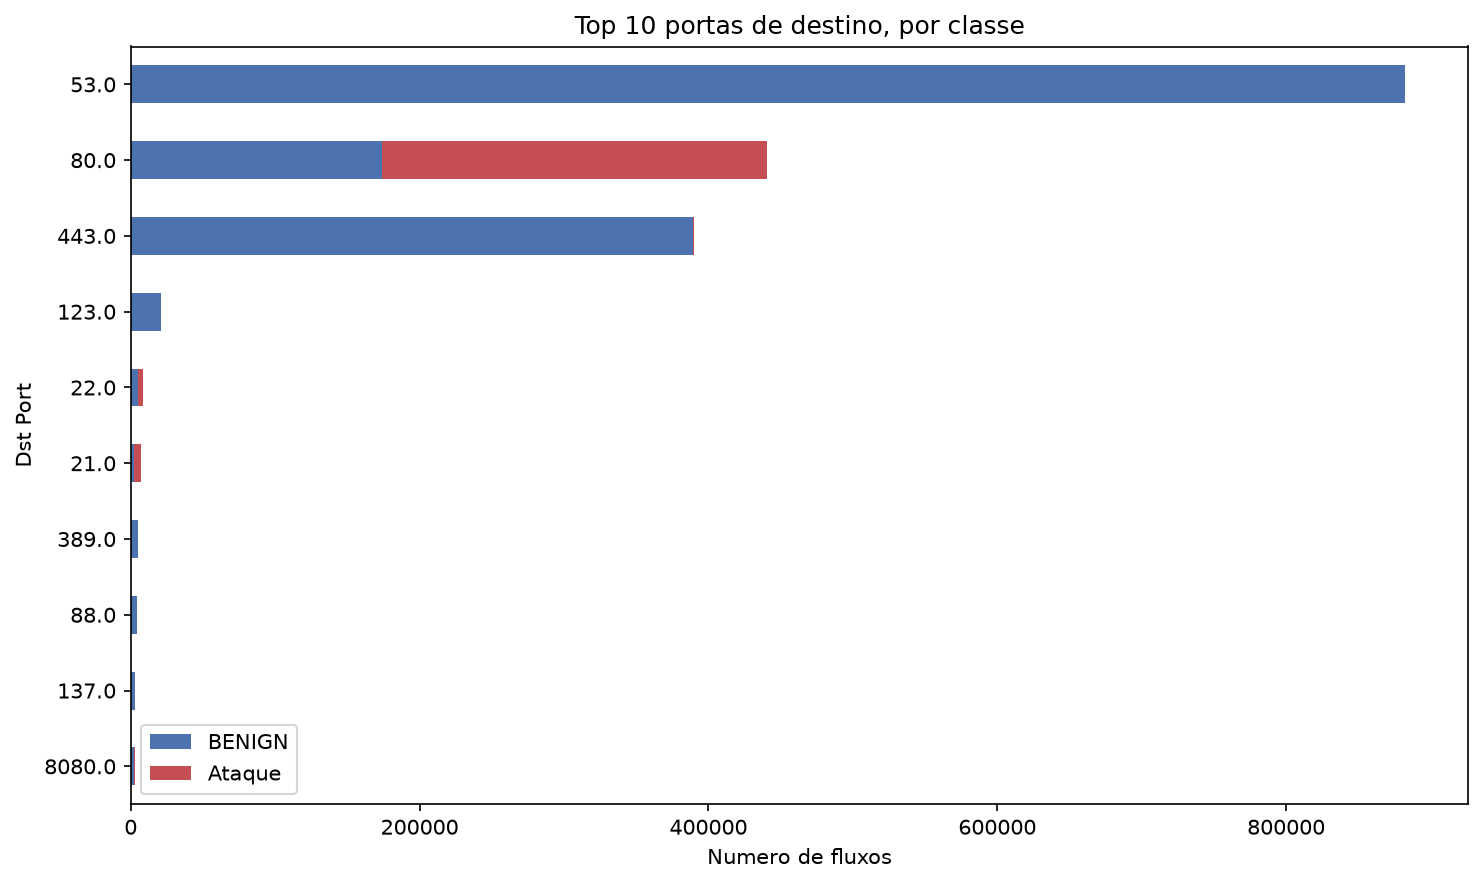

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
tab_portas[["BENIGN", "Ataque"]].plot(kind="barh", stacked=True, ax=ax, color=[COR_BENIGN, COR_ATAQUE])
ax.set_xlabel("Numero de fluxos")
ax.set_title("Top 10 portas de destino, por classe")
ax.invert_yaxis()
fig.tight_layout()
salvar_e_mostrar(fig, "portas_por_classe.png")

In [8]:
tab_protocol = pd.crosstab(df["Protocol"], df["Label_binario"])
tab_protocol.columns = ["BENIGN", "Ataque"]
tab_protocol["pct_ataque"] = (tab_protocol["Ataque"] / (tab_protocol["BENIGN"] + tab_protocol["Ataque"]) * 100).round(2)
tab_protocol.to_csv(MET_DIR / "protocol_por_classe.csv")
tab_protocol

,BENIGN,Ataque,pct_ataque
Protocol,,,
0.0,1567,3,0.19
6.0,631136,364989,36.64
17.0,915333,1,0.00


## 2. Localidade e dispersao

`describe()` sobre os atributos quantitativos (qualitativos nominais de
fora), estendido com IQR, intervalo (max-min), skewness (assimetria) e
contagem de outlier pela regra do boxplot modificado (valor fora de
`[Q1 - 1,5xIQR, Q3 + 1,5xIQR]`) - a "dica pratica" da Aula 2: se o
intervalo for muito maior que o IQR, provavelmente ha outlier.

In [9]:
colunas_numericas = df.select_dtypes(include="number").columns.drop(
    ["Label_multiclasse", "Label_binario", *ATRIBUTOS_QUALITATIVOS_NOMINAIS], errors="ignore"
)

resumo = df[colunas_numericas].describe().T
resumo["IQR"] = resumo["75%"] - resumo["25%"]
resumo["intervalo"] = resumo["max"] - resumo["min"]
resumo["skewness"] = df[colunas_numericas].skew()

limites = {c: limites_iqr(df[c]) for c in colunas_numericas}
resumo["n_outliers_iqr"] = [
    int(((df[c] < limites[c][1]) | (df[c] > limites[c][2])).sum()) for c in colunas_numericas
]
resumo["pct_outliers_iqr"] = (resumo["n_outliers_iqr"] / len(df) * 100).round(3)
resumo.to_csv(MET_DIR / "estatisticas_descritivas.csv")
resumo.loc[ATRIBUTOS_CHAVE, ["mean", "50%", "std", "IQR", "intervalo", "skewness", "pct_outliers_iqr"]]

,mean,50%,std,IQR,intervalo,skewness,pct_outliers_iqr
Flow Duration,1.364171e+07,91973.000000,3.224561e+07,5.321009e+06,1.200000e+08,2.471591,15.532
Total Fwd Packet,1.357306e+01,2.000000,9.119058e+02,6.000000e+00,2.197590e+05,200.898956,9.145
Flow Bytes/s,3.426389e+05,3974.491355,3.199560e+06,3.149975e+04,6.000000e+08,46.681881,19.731
Flow Packets/s,1.145966e+04,64.615136,7.859485e+04,3.237764e+02,5.000000e+06,18.733875,23.855
Packet Length Mean,2.300036e+02,86.000000,3.013098e+02,1.886111e+02,2.125667e+03,1.598858,17.159
SYN Flag Count,9.721965e-01,0.000000,1.092987e+00,2.000000e+00,5.200000e+01,1.060039,0.246
Fwd Packet Length Mean,5.285732e+01,42.000000,9.547460e+01,2.200000e+01,5.775500e+03,14.249997,9.255
Bwd Packet Length Mean,4.469166e+02,125.000000,6.918036e+02,3.430000e+02,4.370687e+03,1.881043,16.893
Flow IAT Mean,9.989655e+05,24118.000000,4.193632e+06,3.732651e+05,6.900004e+07,8.752628,16.572
FWD Init Win Bytes,1.042803e+04,322.000000,1.564267e+04,2.920000e+04,6.553500e+04,1.748519,0.000


### Variancia zero (eliminacao manual, Aula 4)

Atributo com o mesmo valor pra todos os objetos nao carrega informacao
nenhuma pra distinguir os casos (Aula 4) - candidato obvio a remocao na
etapa de selecao (`04_selecao_e_split.py`).

In [10]:
variancia = df[colunas_numericas].var().sort_values()
colunas_variancia_zero = variancia[variancia == 0].index.tolist()
with open(MET_DIR / "colunas_variancia_zero.txt", "w") as f:
    f.write("\n".join(colunas_variancia_zero))
print(f"Colunas com variancia zero: {len(colunas_variancia_zero)} -> {colunas_variancia_zero}")

Colunas com variancia zero: 0 -> []


### Ranking de assimetria (skewness)

Os atributos numericos de fluxo de rede sao notoriamente assimetricos
(poucos fluxos muito longos/intensos puxando a cauda). Ranking dos 15
atributos mais assimetricos entre os 76 quantitativos - quanto maior o
skew, mais a regra de 1,5xIQR (calibrada pra dado proximo do normal, onde
so ~0,7% seria outlier por acaso) vai inflar a contagem de outlier so pela
forma da distribuicao, nao por erro no dado.

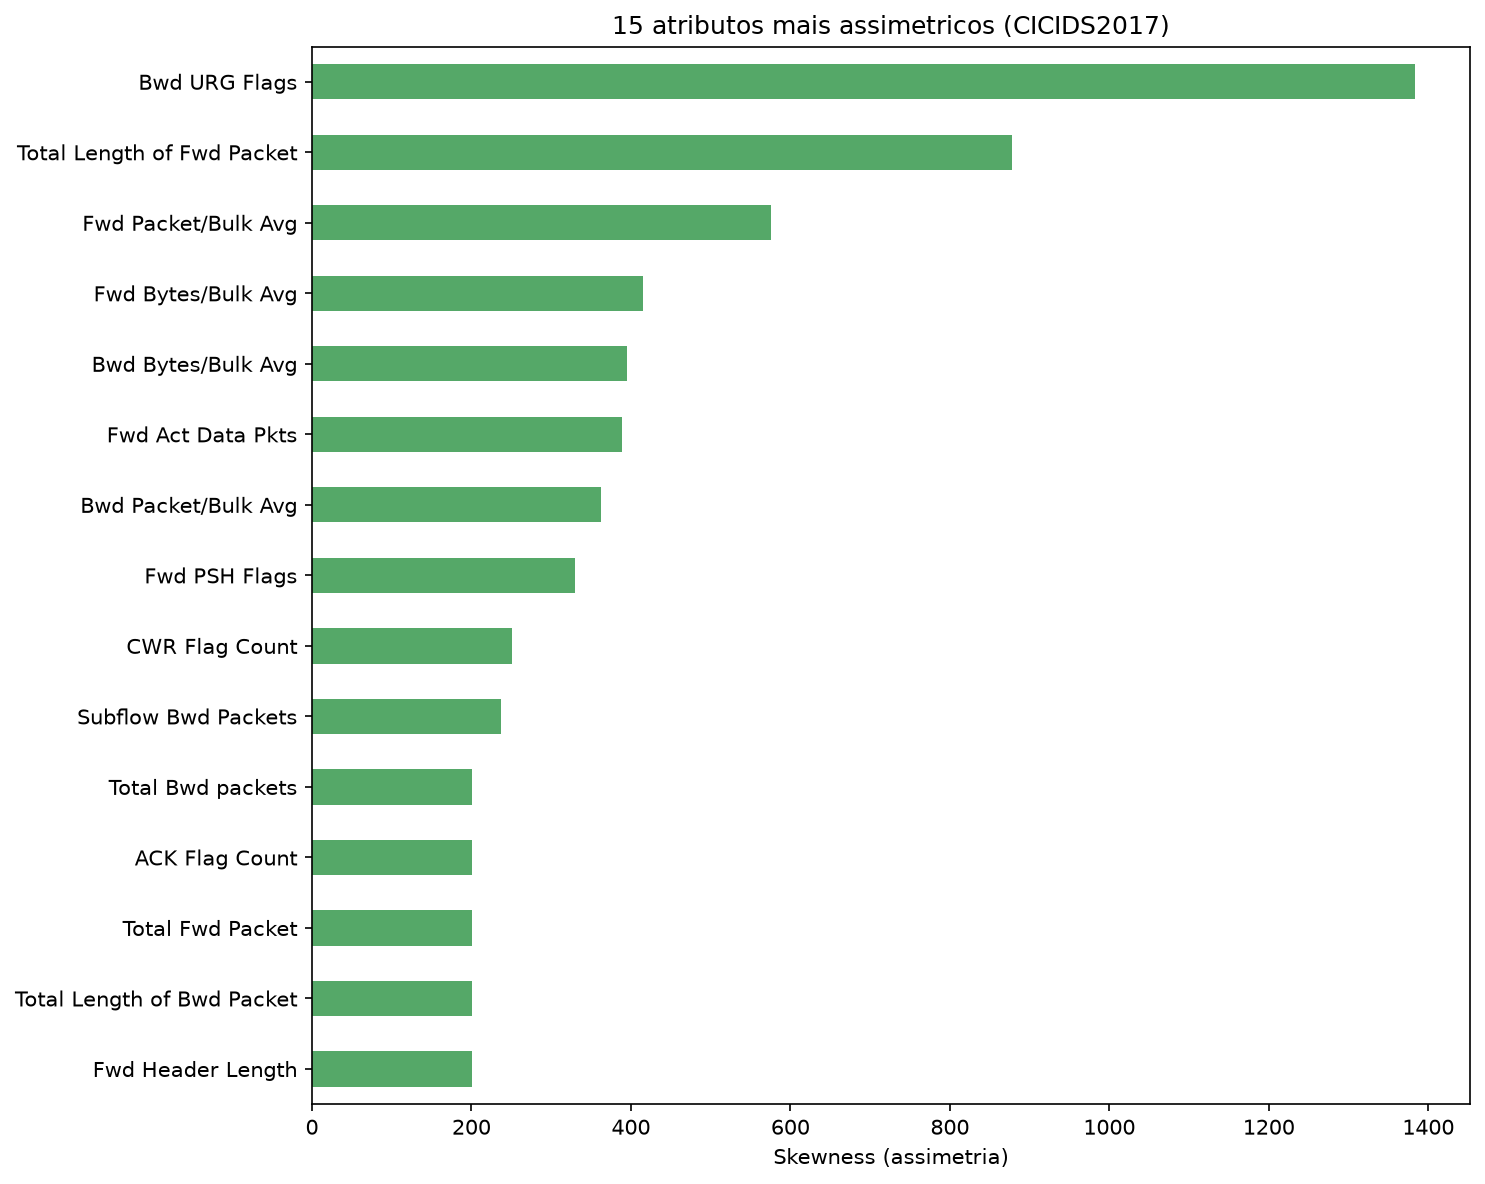

In [11]:
skew_geral = resumo["skewness"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 8))
skew_geral.head(15).plot(kind="barh", ax=ax, color="#55A868")
ax.invert_yaxis()
ax.set_xlabel("Skewness (assimetria)")
ax.set_title("15 atributos mais assimetricos (CICIDS2017)")
fig.tight_layout()
salvar_e_mostrar(fig, "ranking_skewness.png")

### Estatistica descritiva por classe (BENIGN vs ataque)

Media, mediana e desvio padrao dos 12 atributos-chave, separados por
classe - o dado que realmente importa pra um projeto de classificacao:
nao "qual a media geral", mas "esse atributo se comporta diferente entre
trafego benigno e ataque".

In [12]:
describe_por_classe = df.groupby("Label_binario")[ATRIBUTOS_CHAVE].agg(["mean", "median", "std"]).T
describe_por_classe.columns = ["BENIGN", "Ataque"]
describe_por_classe.to_csv(MET_DIR / "estatisticas_por_classe.csv")
describe_por_classe

BENIGN        Ataque
Flow Duration          mean    1.586582e+07  4.208684e+06
                       median  7.157200e+04  1.669990e+05
                       std     3.488635e+07  1.333919e+07
Total Fwd Packet       mean    1.522366e+01  6.572422e+00
                       median  2.000000e+00  7.000000e+00
                       std     1.013658e+03  2.275286e+01
Flow Bytes/s           mean    4.002625e+05  9.824136e+04
                       median  4.093220e+03  2.895880e+03
                       std     3.550109e+06  3.579768e+05
Flow Packets/s         mean    9.904467e+03  1.805564e+04
                       median  6.010970e+01  8.123883e+01
                       std     7.697935e+04  8.479013e+04
Packet Length Mean     mean    1.381512e+02  6.195750e+02
                       median  8.100000e+01  8.036000e+02
                       std     1.767195e+02  3.947657e+02
SYN Flag Count         mean    7.740343e-01  1.812657e+00
                       median  0.000000e+00  2.000000e+00
                       std     1.092052e+00  5.747693e-01
Fwd Packet Length Mean mean    5.879042e+01  2.769341e+01
                       median  4.300000e+01  2.857143e+00
                       std     1.018510e+02  5.473934e+01
Bwd Packet Length Mean mean    2.138257e+02  1.435519e+03
                       median  1.140000e+02  1.932500e+03
                       std     2.987235e+02  9.603085e+02
Flow IAT Mean          mean    1.136882e+06  4.140249e+05
                       median  3.027100e+04  1.332975e+04
                       std     4.528925e+06  2.181662e+06
FWD Init Win Bytes     mean    8.195453e+03  1.989699e+04
                       median  0.000000e+00  2.920000e+04
                       std     1.561921e+04  1.170481e+04
Down/Up Ratio          mean    9.376696e-01  8.308757e-01
                       median  1.000000e+00  8.571429e-01
                       std     2.528180e-01  2.003386e-01
ACK Flag Count         mean    3.022728e+01  1.013998e+01
                       median  0.000000e+00  1.100000e+01
                       std     2.361790e+03  4.288763e+01

## 3. Distribuicao (forma)

A Aula 2 fecha a secao de dados multivariados com o aviso do Quarteto de
Anscombe e do Datasaurus Dozen: estatisticas resumidas (media, variancia,
correlacao) podem ser identicas para dados com formas completamente
diferentes - "nunca confiar so nos numeros, sempre visualizar". Por isso
geramos boxplot e histograma pra 12 atributos-chave, cobrindo familias
diferentes (duracao, contagem, taxa, tamanho fwd/bwd, flag, tempo entre
pacotes, janela TCP, proporcao down/up), alem da tabela numerica acima -
tanto na versao agregada (dataset inteiro) quanto separada por classe.

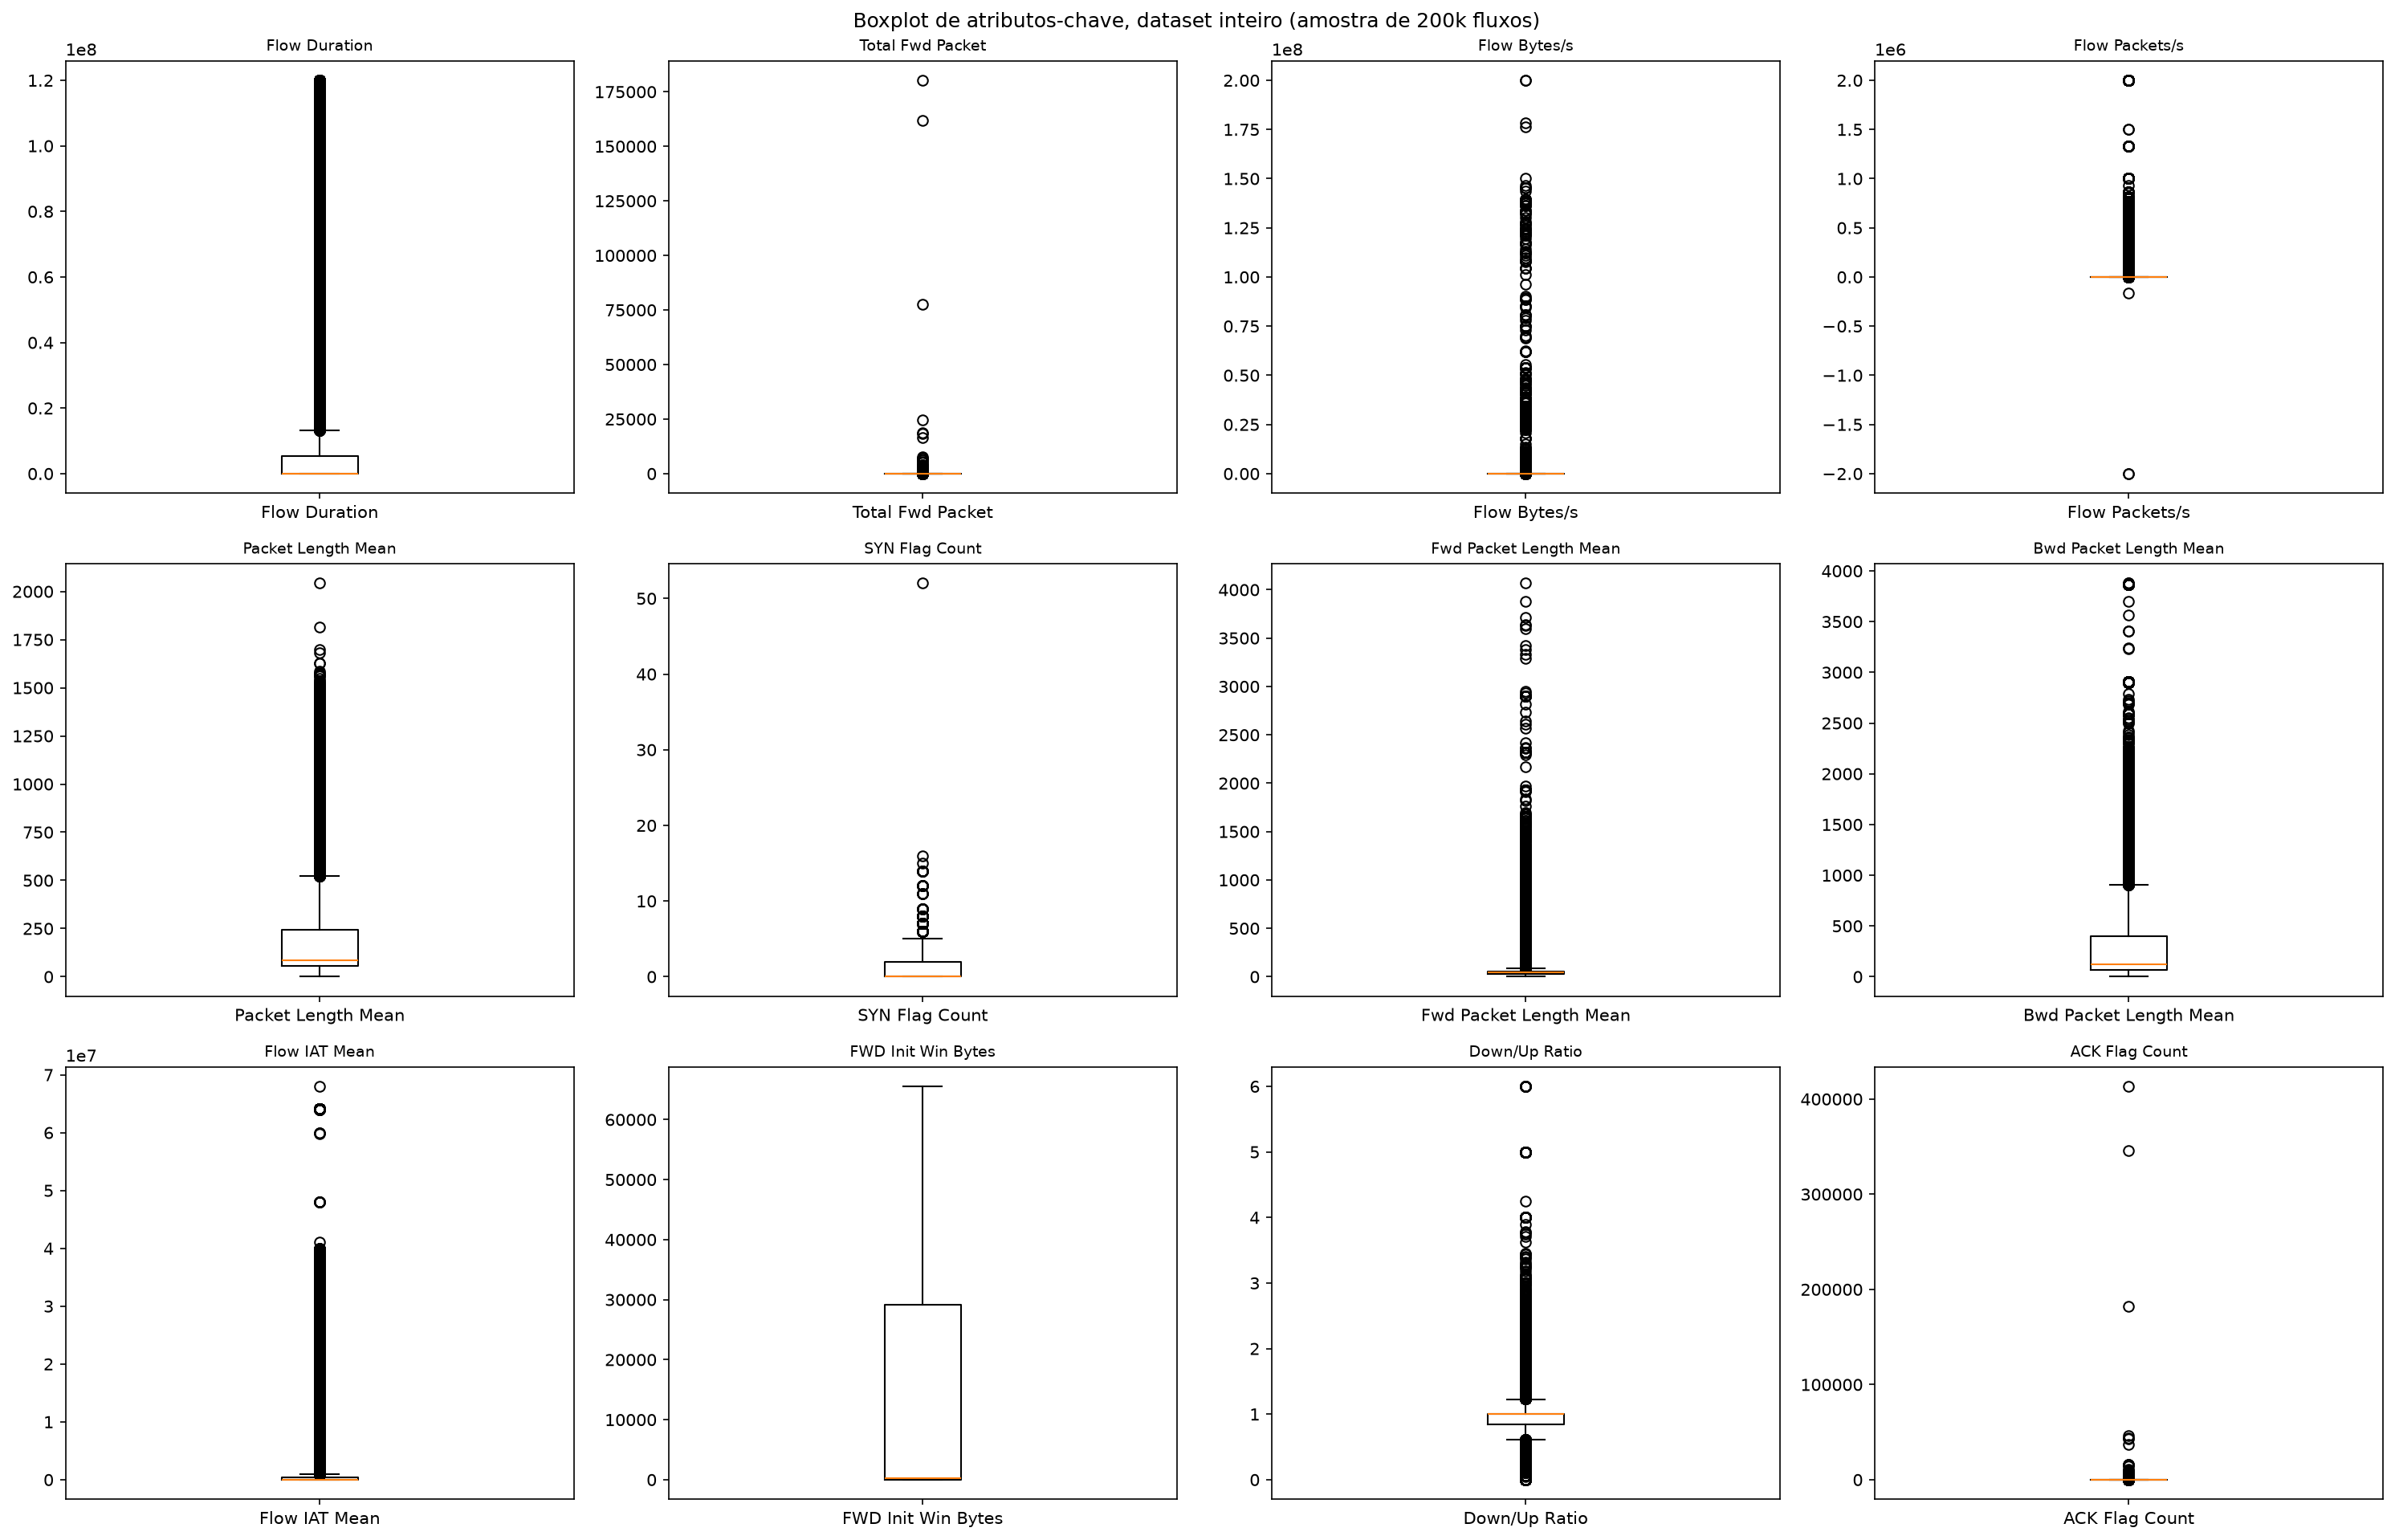

In [13]:
amostra_geral = df[[*colunas_numericas, *ATRIBUTOS_QUALITATIVOS_NOMINAIS, "Label_binario"]].sample(
    n=min(200_000, len(df)), random_state=42
)

fig, axes = plt.subplots(3, 4, figsize=(20, 13))
for ax, col in zip(axes.flat, ATRIBUTOS_CHAVE):
    ax.boxplot(amostra_geral[col].dropna(), tick_labels=[col])
    ax.set_title(col, fontsize=9)
fig.suptitle("Boxplot de atributos-chave, dataset inteiro (amostra de 200k fluxos)")
fig.tight_layout()
salvar_e_mostrar(fig, "boxplots_atributos_chave.png")

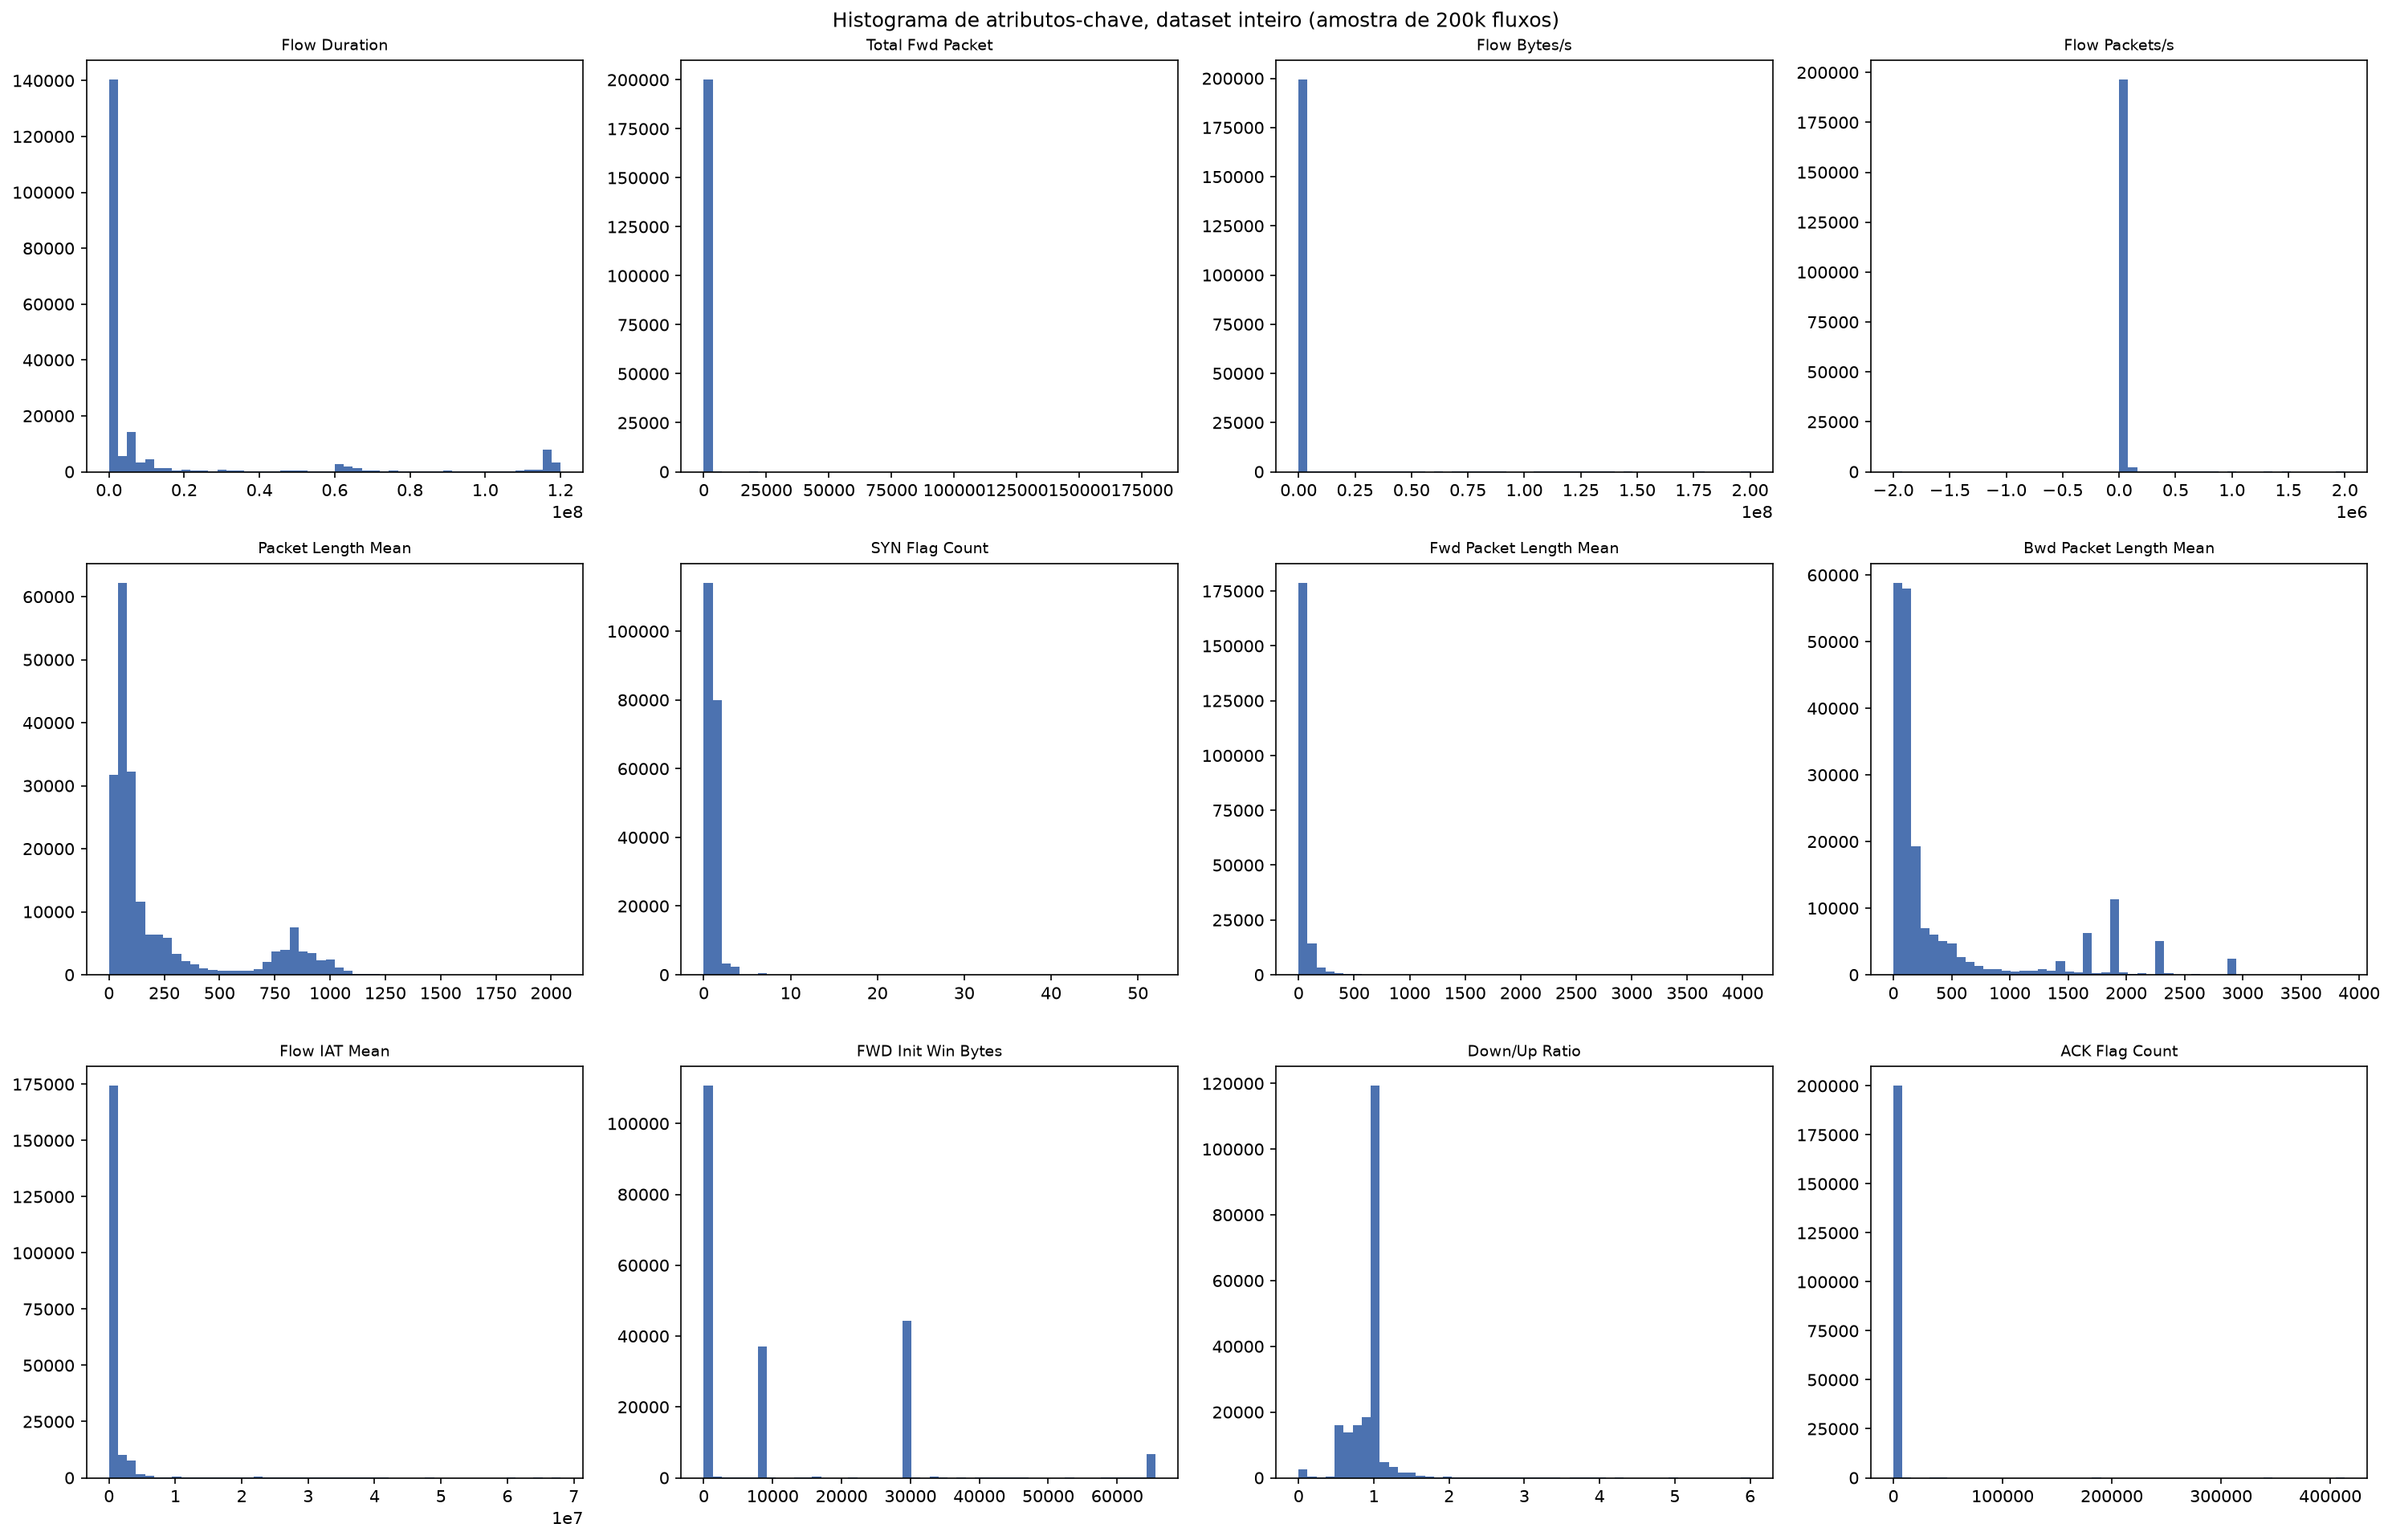

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(20, 13))
for ax, col in zip(axes.flat, ATRIBUTOS_CHAVE):
    ax.hist(amostra_geral[col].dropna(), bins=50, color=COR_BENIGN)
    ax.set_title(col, fontsize=9)
fig.suptitle("Histograma de atributos-chave, dataset inteiro (amostra de 200k fluxos)")
fig.tight_layout()
salvar_e_mostrar(fig, "histogramas_atributos_chave.png")

### Boxplot por classe

Os mesmos 12 atributos, agora com BENIGN e Ataque lado a lado em cada
painel - visualiza diretamente se o atributo parece separar as duas
classes (relevante pra selecao de atributos e pra H1/H2 da proposta).

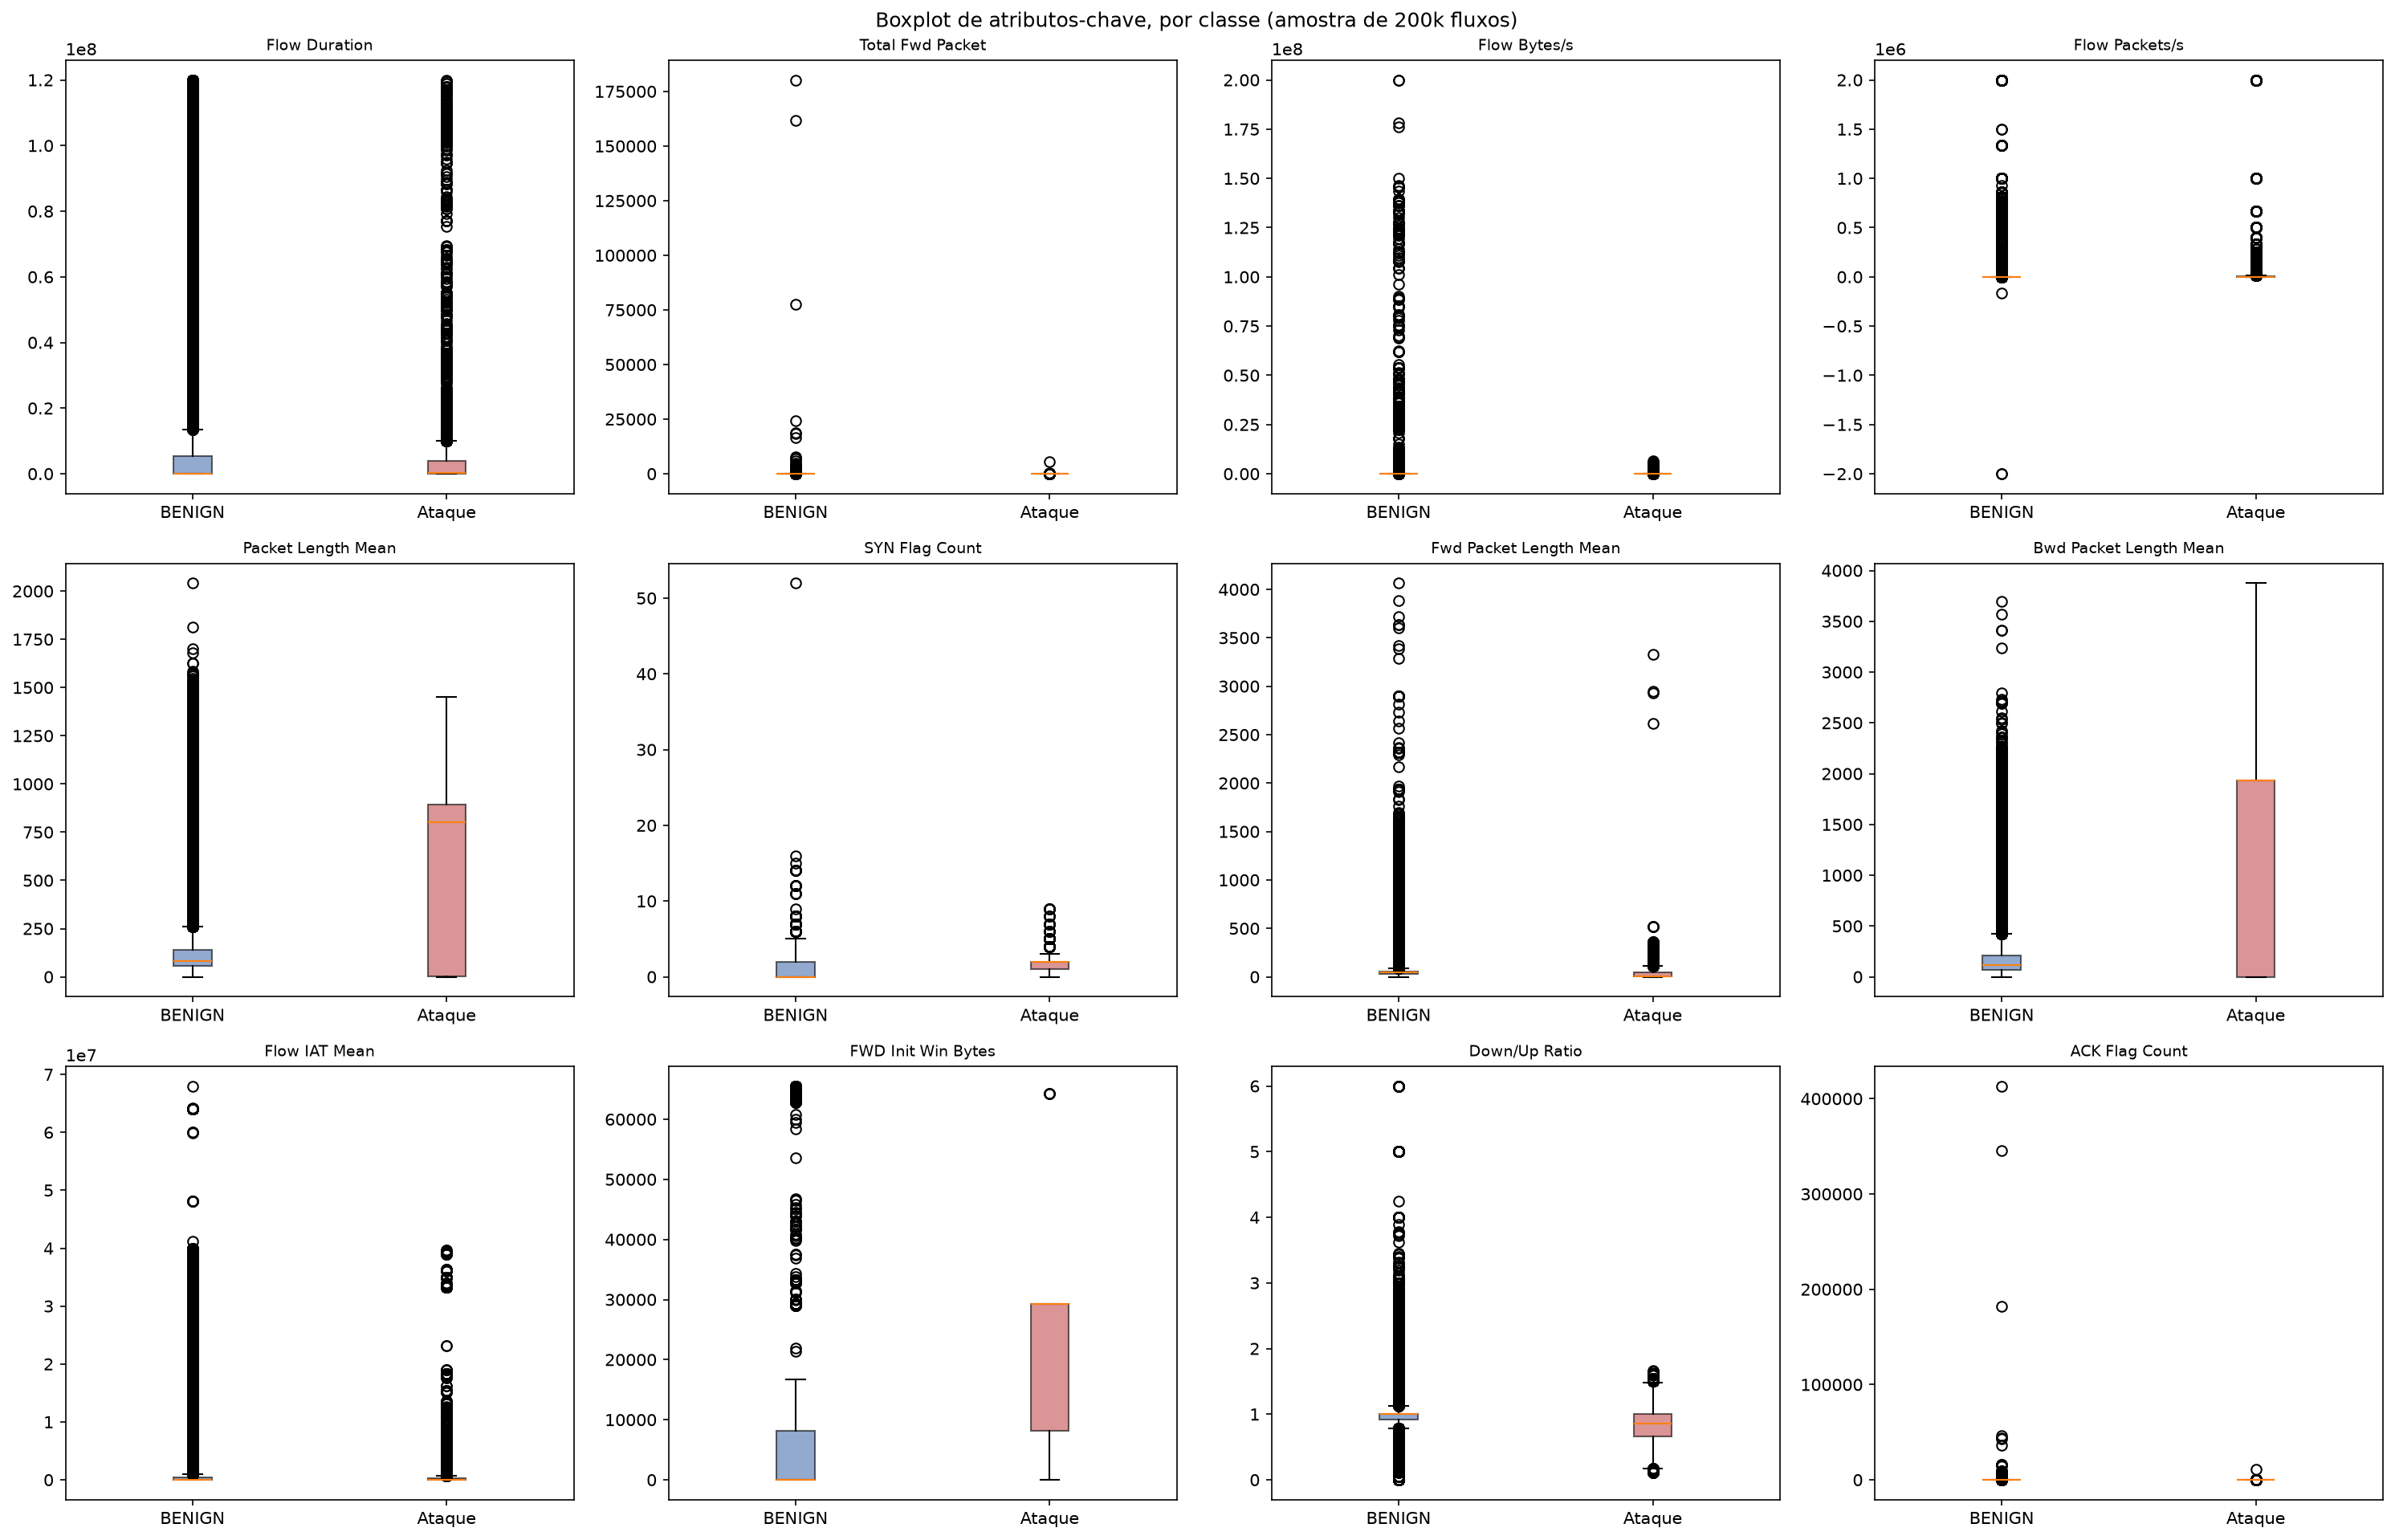

In [15]:
grupo_benign = amostra_geral[amostra_geral["Label_binario"] == 0]
grupo_ataque = amostra_geral[amostra_geral["Label_binario"] == 1]

fig, axes = plt.subplots(3, 4, figsize=(20, 13))
for ax, col in zip(axes.flat, ATRIBUTOS_CHAVE):
    dados = [grupo_benign[col].dropna(), grupo_ataque[col].dropna()]
    bp = ax.boxplot(dados, tick_labels=["BENIGN", "Ataque"], patch_artist=True)
    for patch, cor in zip(bp["boxes"], [COR_BENIGN, COR_ATAQUE]):
        patch.set_facecolor(cor)
        patch.set_alpha(0.6)
    ax.set_title(col, fontsize=9)
fig.suptitle("Boxplot de atributos-chave, por classe (amostra de 200k fluxos)")
fig.tight_layout()
salvar_e_mostrar(fig, "boxplots_por_classe.png")

## 4. Outlier via IQR: e mesmo sinal de ataque?

A Aula 2 e explicita que outlier "nem sempre e erro, pode ser um caso
legitimo, so raro" - mas isso nao pode ficar em especulacao. Aqui testamos
de verdade, pra cada atributo-chave: qual a proporcao de ataque *entre* os
outliers desse atributo, comparada com a proporcao de ataque na base
inteira (19,1%). Se o outlier fosse majoritariamente sinal de ataque, a
proporcao entre outliers seria bem maior que a base.

In [16]:
taxa_base = df["Label_binario"].mean() * 100
linhas = []
for col in ATRIBUTOS_CHAVE:
    iqr, lo, hi = limites_iqr(df[col])
    mask = (df[col] < lo) | (df[col] > hi)
    n = int(mask.sum())
    taxa_outlier = df.loc[mask, "Label_binario"].mean() * 100 if n > 0 else float("nan")
    linhas.append(
        {
            "atributo": col,
            "n_outliers": n,
            "pct_outliers_da_base": round(n / len(df) * 100, 3),
            "pct_ataque_entre_outliers": round(taxa_outlier, 2),
            "pct_ataque_na_base": round(taxa_base, 2),
            "enriquecimento": round(taxa_outlier / taxa_base, 2) if n > 0 else float("nan"),
        }
    )
tab_enriquecimento = pd.DataFrame(linhas).set_index("atributo")
tab_enriquecimento.to_csv(MET_DIR / "outliers_enriquecimento_ataque.csv")
tab_enriquecimento

,n_outliers,pct_outliers_da_base,pct_ataque_entre_outliers,pct_ataque_na_base,enriquecimento
atributo,,,,,
Flow Duration,297132,15.532,4.65,19.08,0.24
Total Fwd Packet,174937,9.145,1.88,19.08,0.10
Flow Bytes/s,377458,19.731,14.11,19.08,0.74
Flow Packets/s,456358,23.855,22.33,19.08,1.17
Packet Length Mean,328256,17.159,78.89,19.08,4.14
SYN Flag Count,4699,0.246,3.55,19.08,0.19
Fwd Packet Length Mean,177053,9.255,10.09,19.08,0.53
Bwd Packet Length Mean,323171,16.893,80.13,19.08,4.20
Flow IAT Mean,317021,16.572,7.23,19.08,0.38


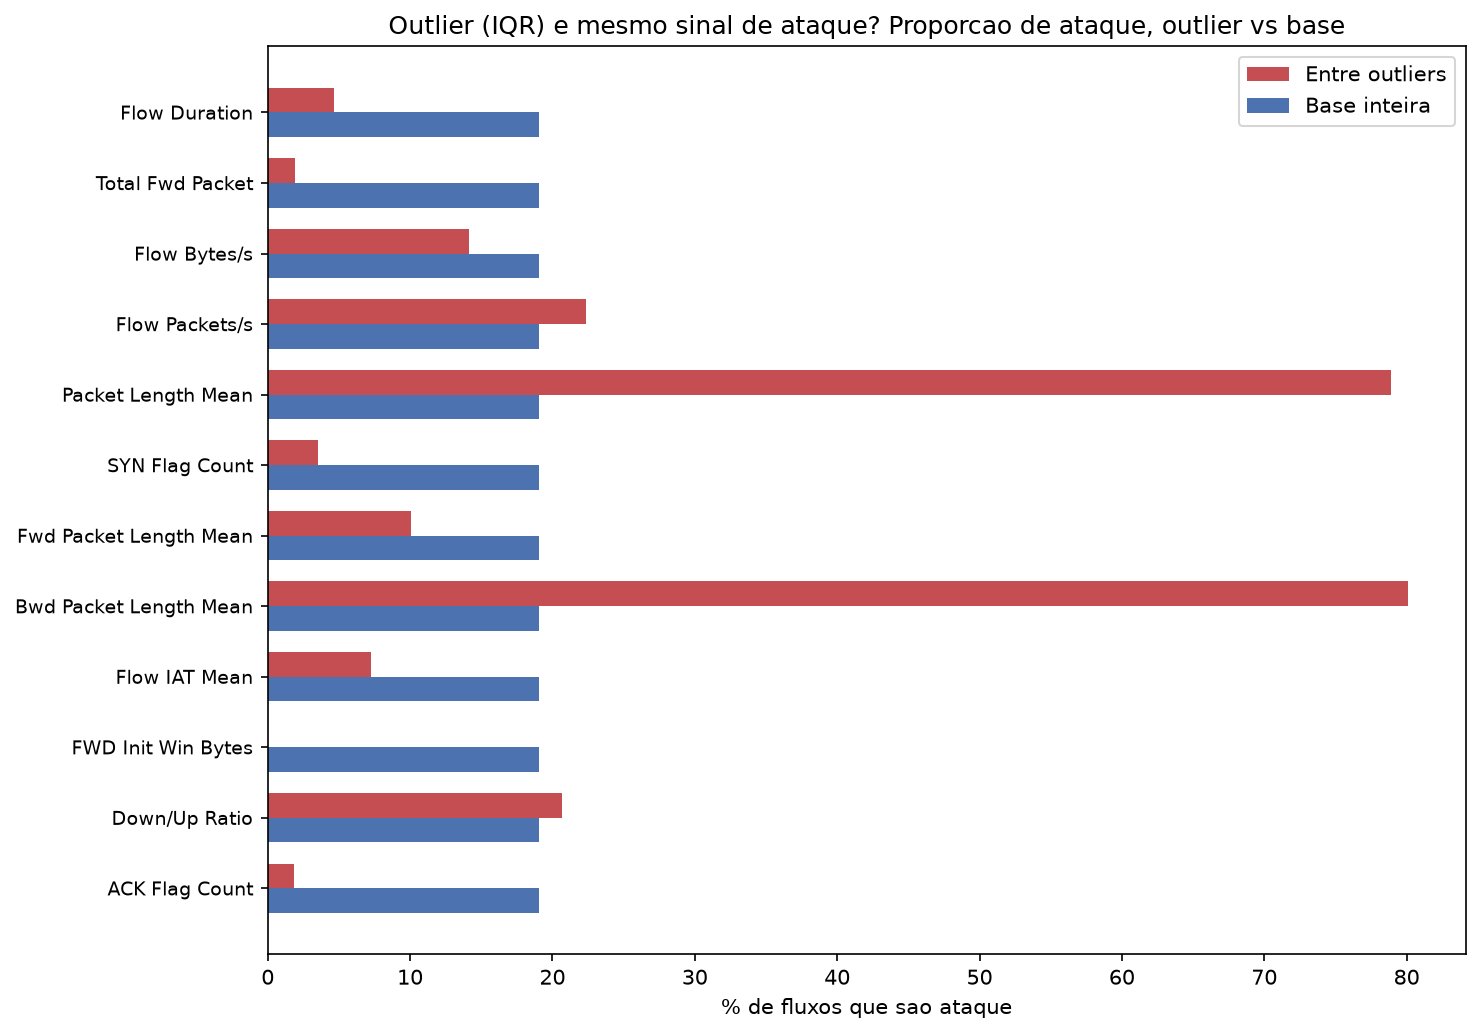

In [17]:
fig, ax = plt.subplots(figsize=(10, 7))
x = np.arange(len(tab_enriquecimento))
largura = 0.35
ax.barh(x - largura / 2, tab_enriquecimento["pct_ataque_entre_outliers"], largura, label="Entre outliers", color=COR_ATAQUE)
ax.barh(x + largura / 2, tab_enriquecimento["pct_ataque_na_base"], largura, label="Base inteira", color=COR_BENIGN)
ax.set_yticks(x)
ax.set_yticklabels(tab_enriquecimento.index, fontsize=9)
ax.set_xlabel("% de fluxos que sao ataque")
ax.set_title("Outlier (IQR) e mesmo sinal de ataque? Proporcao de ataque, outlier vs base")
ax.legend()
ax.invert_yaxis()
fig.tight_layout()
salvar_e_mostrar(fig, "outliers_enriquecimento_ataque.png")

**Leitura:** enriquecimento perto de 1,0x significa que o outlier daquele
atributo nao concentra ataque mais que o esperado pela proporcao geral -
ou seja, e majoritariamente cauda longa de trafego benigno normal (conexao
persistente, rajada legitima), nao sinal de ataque. Enriquecimento bem
acima de 1,0x indica que outlier daquele atributo especifico *e* um bom
sinal pra separar ataque de benigno.

## 5. Correlacao

Matriz de correlacao de Pearson so entre os atributos quantitativos
(`Protocol`/`Dst Port` de fora, pelo motivo explicado no topo) - amostra
de 200k fluxos por custo computacional. Base para a selecao de atributos
do script `04_selecao_e_split.py` (remocao de redundancia por
correlacao > 0,95). Alem do heatmap, olhamos a distribuicao dos
coeficientes par-a-par (pra justificar o limiar de 0,95) e a correlacao
de cada atributo com o proprio alvo (`Label_binario`).

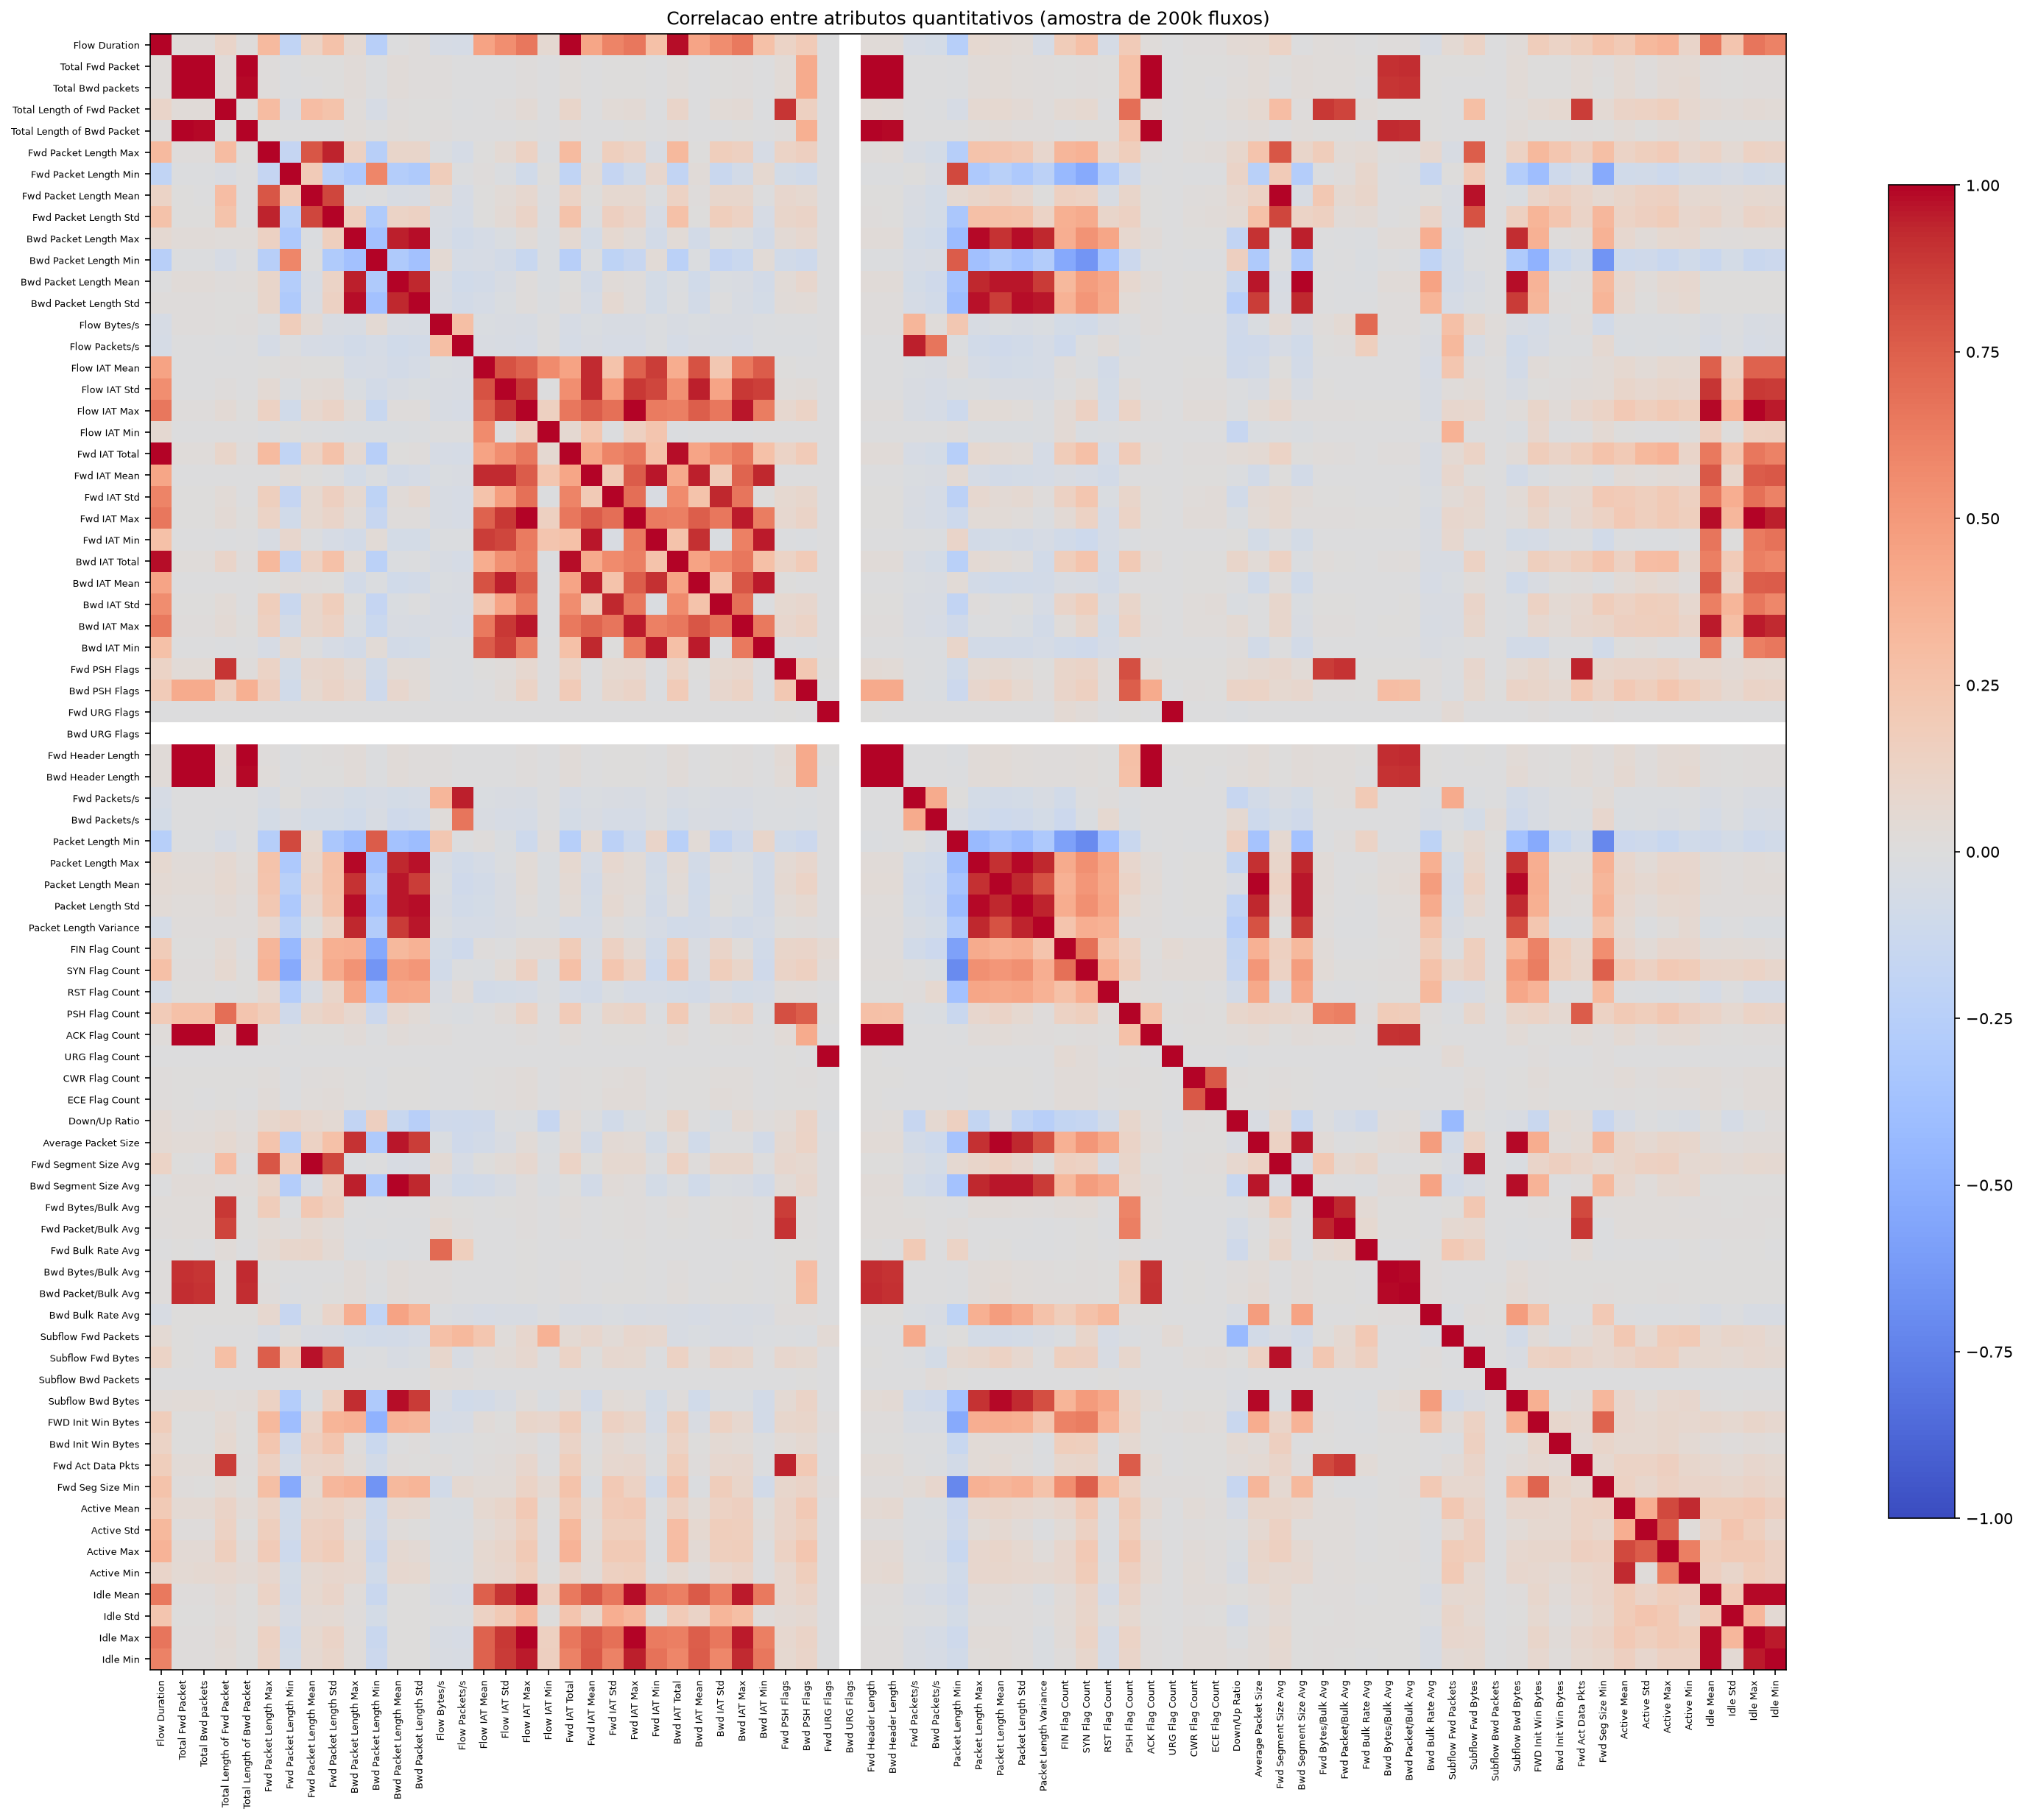

In [18]:
corr = amostra_geral[colunas_numericas].corr(numeric_only=True)
corr.to_csv(MET_DIR / "matriz_correlacao.csv")

fig, ax = plt.subplots(figsize=(20, 18))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=6)
ax.set_yticklabels(corr.columns, fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title("Correlacao entre atributos quantitativos (amostra de 200k fluxos)")
fig.tight_layout()
salvar_e_mostrar(fig, "matriz_correlacao.png")

Pares de atributos: 2850
Pares com |r| > 0,95: 61 (2.14%)


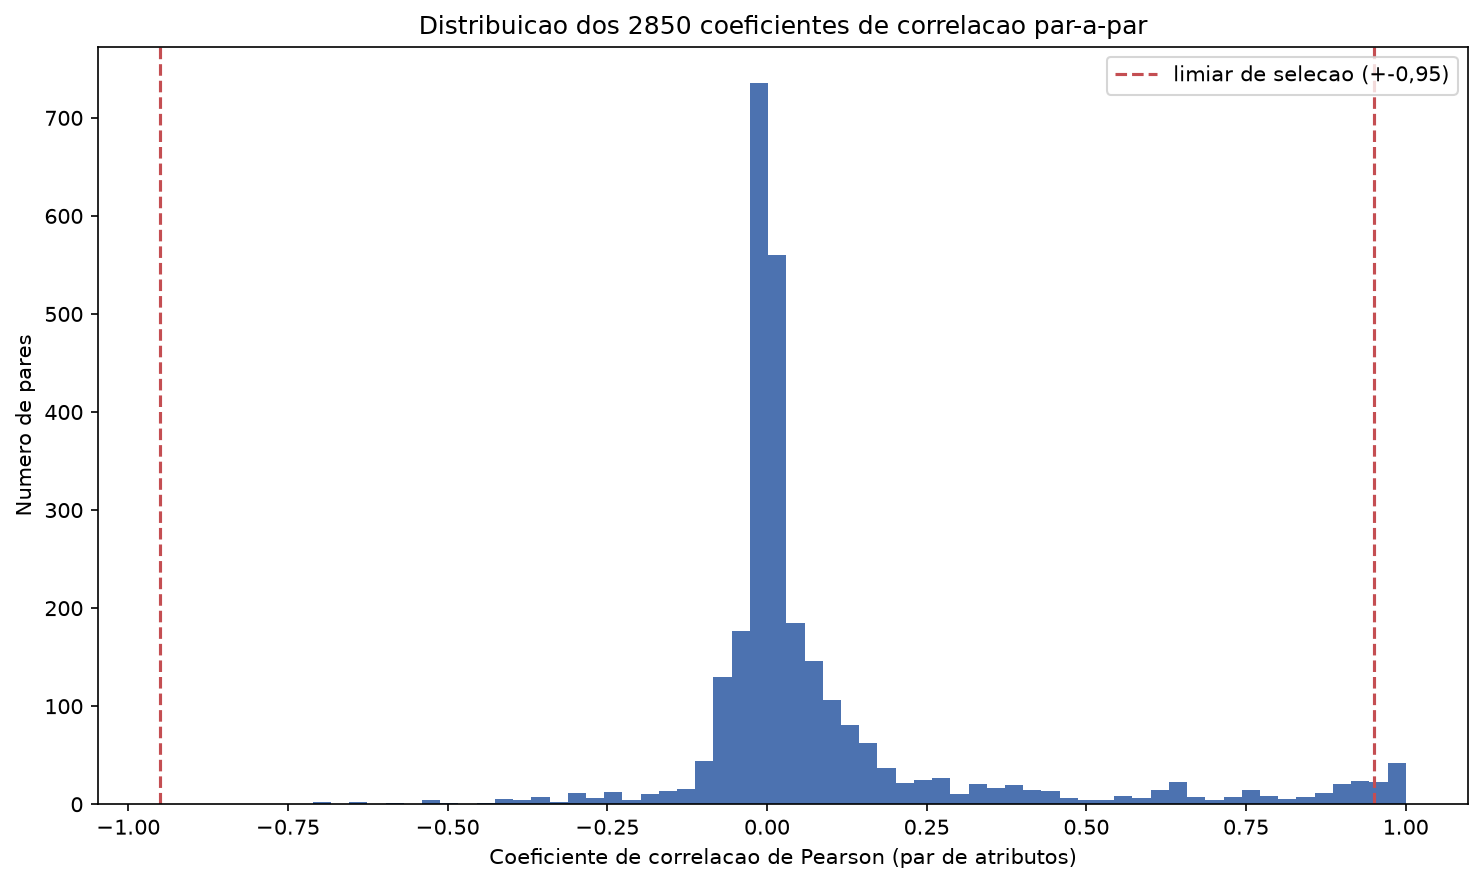

In [19]:
triu_idx = np.triu_indices_from(corr.values, k=1)
coef_pares = corr.values[triu_idx]
n_acima_limiar = int((np.abs(coef_pares) > 0.95).sum())
print(f"Pares de atributos: {len(coef_pares)}")
print(f"Pares com |r| > 0,95: {n_acima_limiar} ({n_acima_limiar / len(coef_pares) * 100:.2f}%)")

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(coef_pares, bins=60, color=COR_BENIGN)
ax.axvline(0.95, color=COR_ATAQUE, linestyle="--", label="limiar de selecao (+-0,95)")
ax.axvline(-0.95, color=COR_ATAQUE, linestyle="--")
ax.set_xlabel("Coeficiente de correlacao de Pearson (par de atributos)")
ax.set_ylabel("Numero de pares")
ax.set_title(f"Distribuicao dos {len(coef_pares)} coeficientes de correlacao par-a-par")
ax.legend()
fig.tight_layout()
salvar_e_mostrar(fig, "distribuicao_coeficientes_correlacao.png")

### Correlacao de cada atributo com o alvo

Correlacao de Pearson entre cada atributo quantitativo e `Label_binario`
(0=BENIGN, 1=ataque) - e a mesma tecnica de correlacao da Aula 2, so que
contra o alvo em vez de entre atributos. Nao decide sozinha quais
atributos entram no modelo (Pearson so capta relacao linear, e o alvo e
binario), mas da uma primeira leitura de quais atributos parecem separar
melhor as classes.

In [20]:
corr_alvo = amostra_geral[colunas_numericas].corrwith(amostra_geral["Label_binario"]).sort_values(
    key=lambda s: s.abs(), ascending=False
)
corr_alvo.to_csv(MET_DIR / "correlacao_com_alvo.csv", header=["correlacao_com_label_binario"])
corr_alvo.head(20)

.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Bwd Packet Length Std     0.699503
Packet Length Std         0.695613
Bwd Packet Length Mean    0.692581
Bwd Segment Size Avg      0.692581
Bwd Packet Length Max     0.681435
Packet Length Variance    0.673718
Packet Length Max         0.668926
Subflow Bwd Bytes         0.650574
Packet Length Mean        0.626081
Average Packet Size       0.626081
RST Flag Count            0.493065
Fwd Seg Size Min          0.449887
Bwd Bulk Rate Avg         0.441933
Packet Length Min        -0.384838
SYN Flag Count            0.373275
Bwd Packet Length Min    -0.353067
FWD Init Win Bytes        0.293368
Fwd Packet Length Min    -0.285760
Down/Up Ratio            -0.171829
Bwd IAT Total            -0.162930
dtype: float64

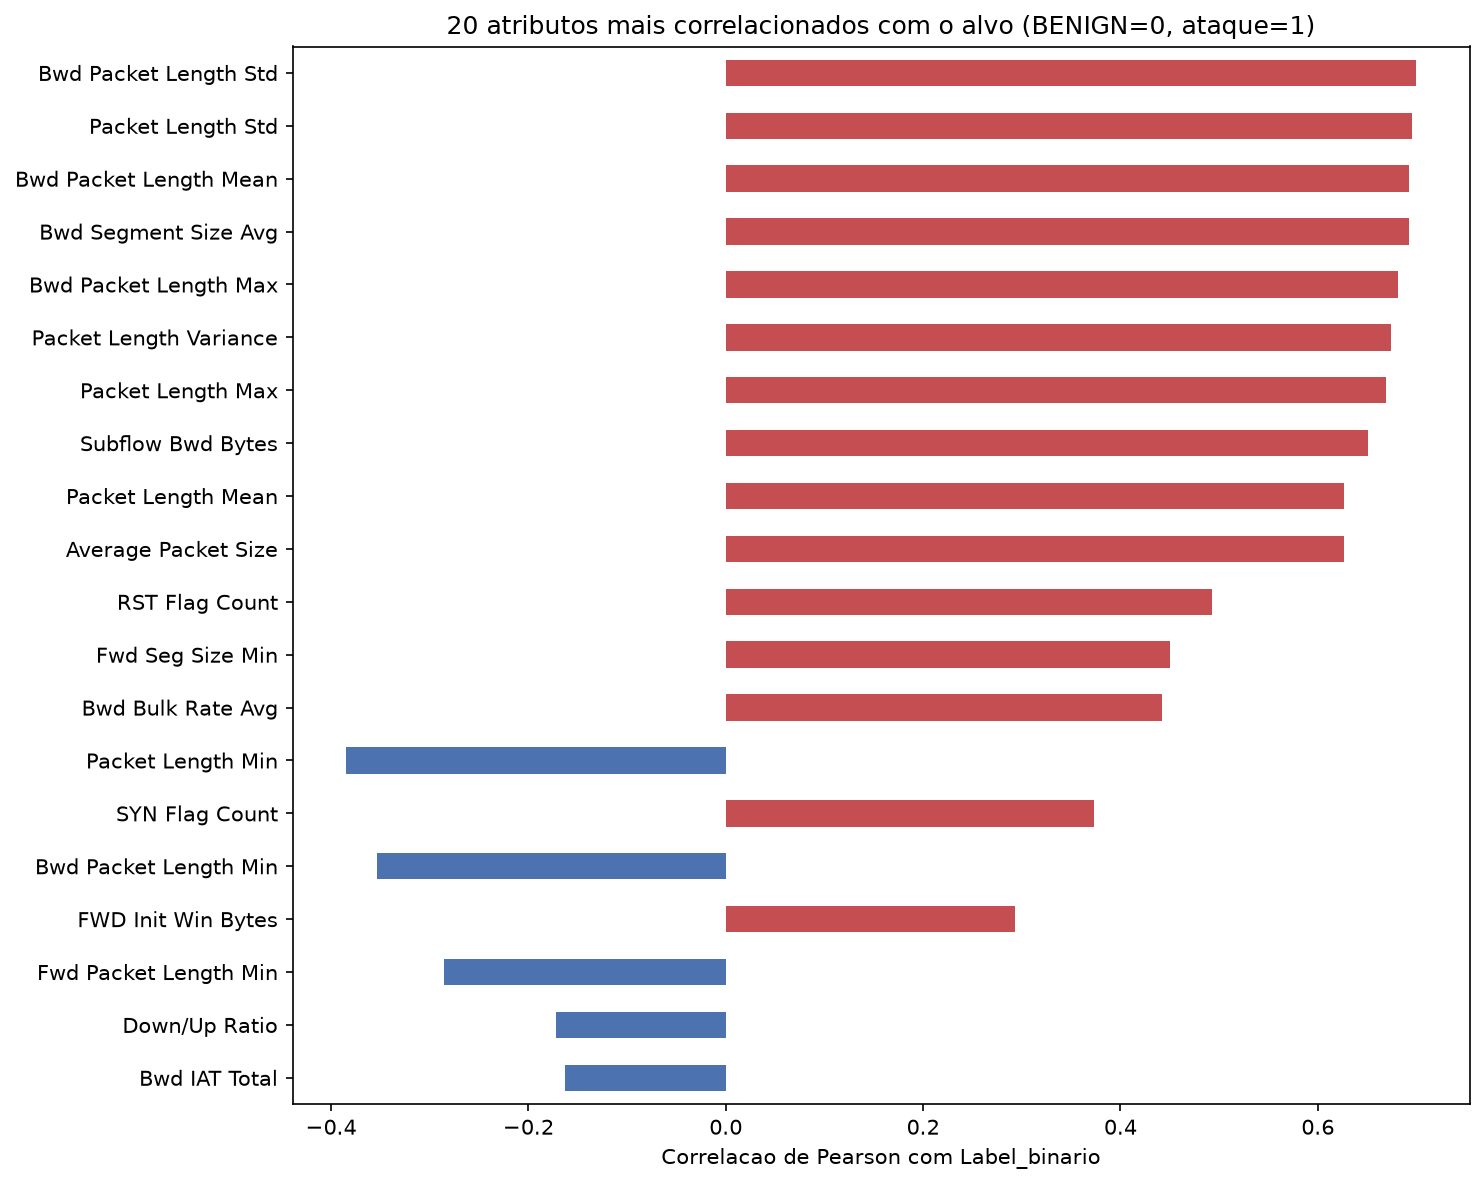

In [21]:
top20 = corr_alvo.head(20)
cores = [COR_ATAQUE if v > 0 else COR_BENIGN for v in top20]
fig, ax = plt.subplots(figsize=(10, 8))
top20.plot(kind="barh", ax=ax, color=cores)
ax.invert_yaxis()
ax.set_xlabel("Correlacao de Pearson com Label_binario")
ax.set_title("20 atributos mais correlacionados com o alvo (BENIGN=0, ataque=1)")
fig.tight_layout()
salvar_e_mostrar(fig, "correlacao_com_alvo.png")

### Pair plot de atributos-chave, colorido por classe

Matriz de dispersao (scatter matrix) de 6 atributos-chave, ponto colorido
por classe - a Aula 2 cita pair plot como a ferramenta multivariada pra
quando o heatmap sozinho nao mostra a forma da relacao entre pares (o
aviso do Datasaurus/Anscombe de novo: correlacao numerica igual pode
esconder nuvens de pontos bem diferentes). Amostra menor aqui (15k) so por
custo de renderizacao do grid 6x6.

Esses 6 atributos sao os mais assimetricos do conjunto-chave (skew de 2,5 a
quase 200 - ver ranking de skewness acima); em escala bruta, a nuvem de
pontos fica esmagada num canto do grafico e a maior parte da figura vira
espaco vazio. Aplicamos `log1p` (log(1+x), que aceita zero sem erro) só
para esse gráfico, prática padrão em dado de rede com esse nível de
assimetria - os valores em si continuam os mesmos usados em todas as
outras análises, aqui é só a escala de exibição que muda.

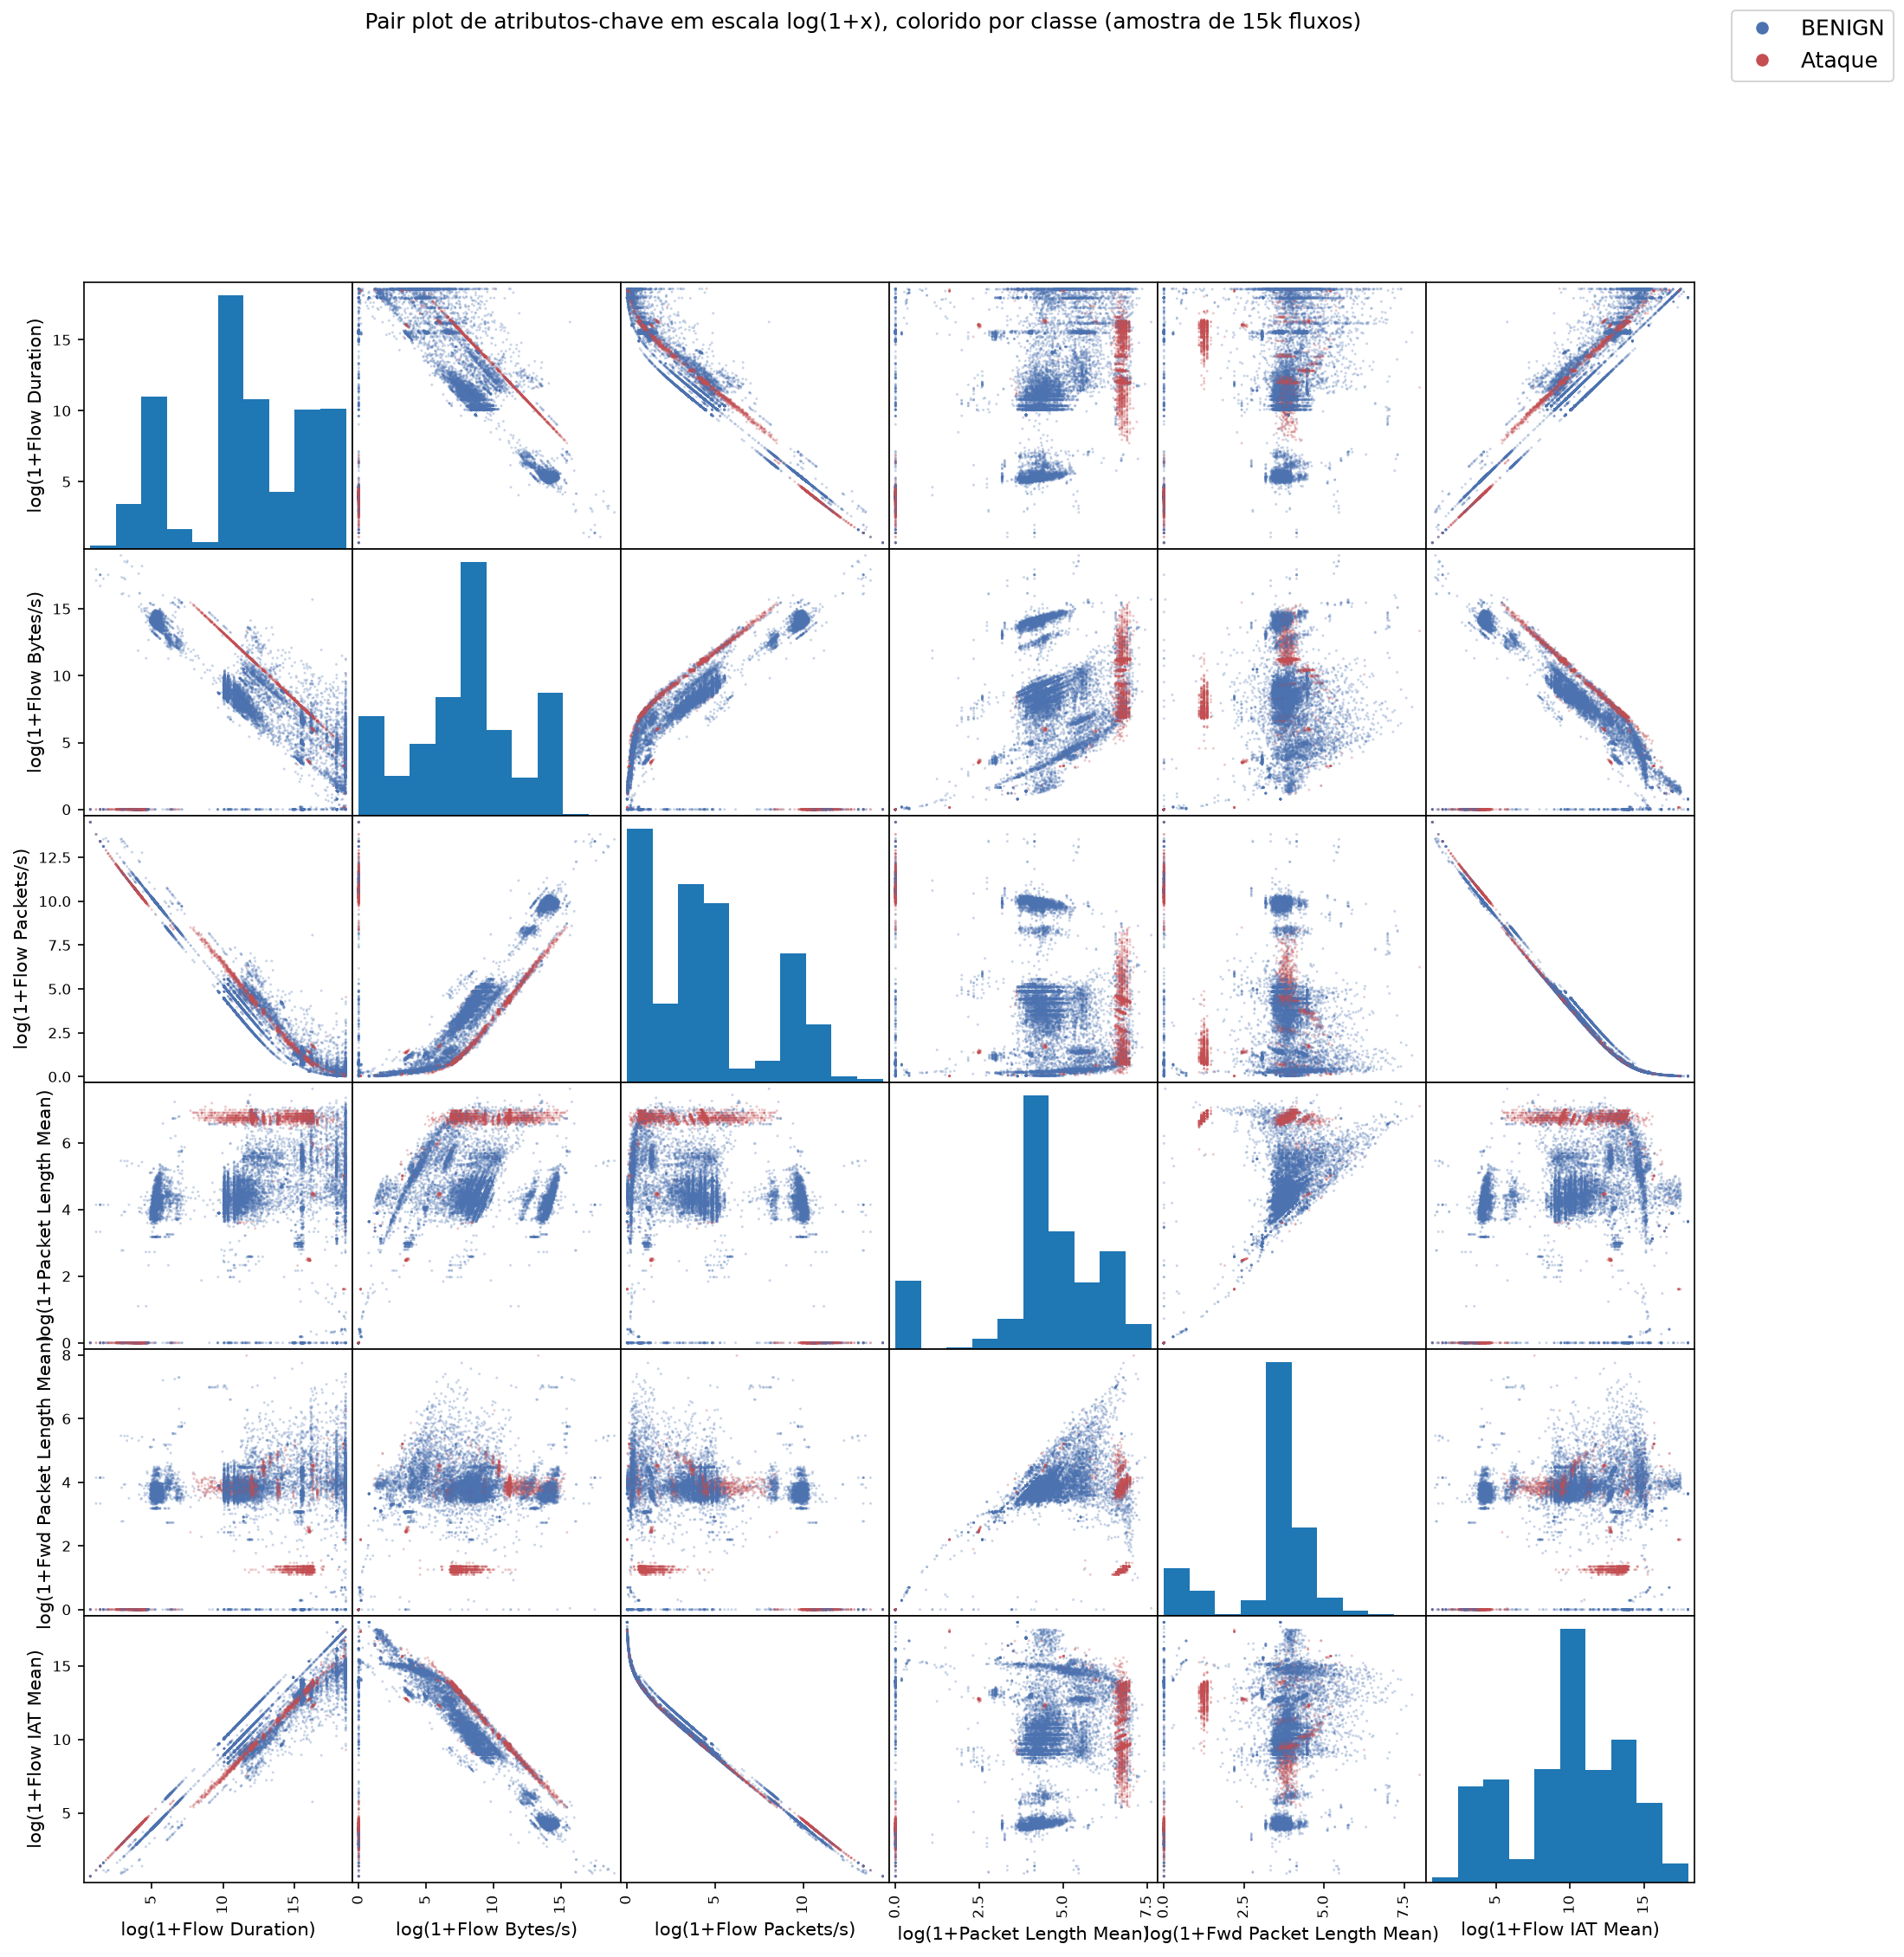

In [22]:
amostra_pairplot = amostra_geral.sample(n=min(15_000, len(amostra_geral)), random_state=42)
cores_pontos = amostra_pairplot["Label_binario"].map({0: COR_BENIGN, 1: COR_ATAQUE})
dados_pairplot_log = np.log1p(amostra_pairplot[ATRIBUTOS_PAIRPLOT].clip(lower=0))
dados_pairplot_log.columns = [f"log(1+{c})" for c in ATRIBUTOS_PAIRPLOT]

axes_arr = pd.plotting.scatter_matrix(
    dados_pairplot_log,
    figsize=(16, 16),
    diagonal="hist",
    alpha=0.3,
    s=8,
    c=cores_pontos,
)
fig = axes_arr[0, 0].get_figure()
legenda = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=COR_BENIGN, markersize=8, label="BENIGN"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=COR_ATAQUE, markersize=8, label="Ataque"),
]
fig.legend(handles=legenda, loc="upper right", fontsize=12)
fig.suptitle("Pair plot de atributos-chave em escala log(1+x), colorido por classe (amostra de 15k fluxos)", y=1.01)
salvar_e_mostrar(fig, "pairplot_atributos_chave.png")

EDA concluida. Saidas em `../resultados/figuras/` (11 figuras) e
`../resultados/metricas/` (tabelas em CSV).